# ============================================================
# PART 0 - Problem Definition and Dataset Selection
# ============================================================


# 1. Framing the Problem

## Business Objective

Predicting each stock's volatility over the next **5 trading days** using historical market information available at the forecast date.

The goal is to support investment risk management, position sizing, and volatility monitoring, thus not simply predict whether stock prices will rise or fall.

## Project Scope

- **Universe:** Current S&P 500 constituents (503 ticker symbols).
- **Historical period:** January 2020 – October 2026.
- **Observation:** One stock on one trading date.
- **Problem type:** Supervised time-series regression using panel data.
- **Forecast horizon:** Next 5 trading days.

## Forecasting Pipeline

1. Historical Data: adj stock prices and trading volume
2. Returns: calculates daily returns
3. Feature & Target Engineering
    - X: Historical returns, rolling volatility, volume
    - Y: Future 5-d realized variance
4. Model Training: Baseline / Ridge / Rand Forest / XGBoost
5. Forecast / Predict next 5-d realized variance
6. Conversion/Variance: 5-d volatilty
7. Evaluate forecast and risk-use (MAE/RMSE/QLIKE/position sizing/risk monitoring)

## Modeling & Evaluation

- **Primary target:** Future 5-day realized variance, calculated from squared daily log returns.
- **Business output:** 5-day volatility, calculated as the square root of predicted variance.
- **Phase A:** [FOCUS] Compare a historical baseline, Ridge, Random Forest, and XGBoost.
- **Phase B:** [EXTENSION] Extend the comparison with GARCH(1,1), HAR-style benchmarks, and portfolio risk evaluation.
- **Validation:** Chronological train/test split and walk-forward validation, accounting for overlapping forecast horizons.
- **Metrics:** MAE, RMSE, and QLIKE [REMOVED], evaluated on consistent scales.

## Modeling Principles

- Use only information available at the forecast date.
- Prevent leakage between historical predictors and future targets.
- Preserve chronological order and account for missing trading observations.
- Compare models against a simple historical baseline.
- Evaluate out-of-sample performance rather than assuming predictive accuracy.
- Document the current-constituent survivorship bias and preserve data snapshots for reproducibility.


# ============================================================
# PART 1 - Modules & Parameters
# ============================================================

In [1]:
%pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Modules #

# data inspection/manipulation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# data acquisition
import yfinance as yf                               # Downloads historical stock market data
from io import StringIO                             # Reads downloaded HTML tables
# ridge regression
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
# random forest
from sklearn.ensemble import RandomForestRegressor

# Parameters #

# Dataset Configs
DATA_SOURCE = "yfinance"                            # "yfinance" or "csv"
DATA_PATH = None                                    # csv placeholder, assumes csv within directory
CSV_SEPERATOR = ","                                 # csv exclusive
DATASET = None                                      # initializes the variable without loading anything.


# Reproducibility
RS = 69                                             # random state

# Forecast Configs
HZ = 5                                              # nb of future trading days to forecast (e.g. "forecasts next-5-day volatility")
TD = 252                                            # trading days - if annualizing daily volatility (~ trading days/year)

# Standardized Column Names                         # (name of the column containing stock "identifiers")
DATE_COL = "Date"                                   # date field
TICKER_COL = "Ticker"                               # identifier/ticker, pretty fk obvious
PRICE_COL = "Adjusted_Close"                        # adj closing-price field
TARGET = "Future_Variance_5D"                       # Prediction Target y

# Market Data Configs                               # currently = ~6 years and 9.5 months (1,709 trading dates)
START_DATE = "2020-01-01"                           # Historical starting date
END_DATE = "2026-10-21"                             # Latest available data
INTERVAL = "1d"                                     # Daily observations

# Historical Votality
RW = [5, 10, 20]                                    # Rolling windows (trading days)

# CV
CV_SPLITS = 5                                       # Number of walk-forward validation folds

# Representative stocks for visual comparisons
EDA_TICKERS = ["AAPL", "MSFT", "NVDA", "AMD"]

# Validatio0n
print("Project configuration initialized.")
print(f"Forecast horizon: {HZ} trading days")
print(f"Primary target: {TARGET}")

Project configuration initialized.
Forecast horizon: 5 trading days
Primary target: Future_Variance_5D


# ============================================================
# PART 2 - Data Acquisition & Validation
# ============================================================

## 2.1 - Data Acquisition
- documenting what data we expect and where will come from.

Wiki: https://ranaroussi.github.io/yfinance/reference/api/yfinance.Tickers.html

In [3]:
# Select data source and acquire raw data, only one acquisition method executes
if DATA_SOURCE == "yfinance":

    # Retrieve current S&P 500 constituents
    url = "https://raw.githubusercontent.com/datasets/s-and-p-500-companies/refs/heads/main/data/constituents.csv"  # using raw, couldn't load csv otherwise
    constituents = pd.read_csv(url)

    # Locate the table containing stock symbols

    if "Symbol" not in constituents.columns:
        raise ValueError("Ticker column 'Symbol' not found.")

    # Convert stock symbols to Yahoo Finance format
    tickers = (
        constituents["Symbol"]
        .dropna()
        .astype(str)
        .str.strip()
        .str.replace(".", "-", regex = False)
        .drop_duplicates()
        .tolist()
    )

    print(f"S&P symbols retrieved: {len(tickers)}")

    # Download historical adjusted stock prices
    DATASET = yf.download(
        tickers = tickers,                              # selects stocks to dwnload
        start = START_DATE,                             # beg. of hist coverage
        end = END_DATE,                                 # latest available data when "None"
        interval = INTERVAL,                            # 1 observation/trading day
        auto_adjust = True,                             # adjust OHLC (open-high-low-close) prices (makes the historical price series account for splits and dividends)
        group_by = "ticker",                            # groups col by stocks
        progress = False,                               # removes progress bar (download)
        threads = True
    )

    # Identify stocks with no usable closing prices
    if not DATASET.empty:
        downloaded = [
            ticker for ticker in tickers
            if (ticker, "Close") in DATASET.columns
            and DATASET[(ticker, "Close")].notna().any()
        ]

        failed = sorted(set(tickers) - set(downloaded))

        print(f"Stocks with price data: {len(downloaded)} / {len(tickers)}")
        print(f"Stocks without price data: {len(failed)}")

        if failed:
            print("Missing tickers:", failed)

elif DATA_SOURCE == "csv":

    # Load the specified local CSV
    if not DATA_PATH:
        raise ValueError("Set DATA_PATH before using CSV mode.")

    DATASET = pd.read_csv(
        DATA_PATH
    )

else:
    raise ValueError("DATA_SOURCE must be 'yfinance' or 'csv'.")

# Validate acquisition and inspect raw data (ensure dataset contains observations)
if DATASET.empty:
    raise ValueError("No data retrieved. Check the source and configuration.")

print(f"\nSource: {DATA_SOURCE}")
print(f"Dataset shape: {DATASET.shape}")
display(DATASET.head())

# Verify the actual historical coverage
print("Requested start:", START_DATE)
print("First available date:", DATASET.index.min())
print("Last available date:", DATASET.index.max())
print("Trading dates:", len(DATASET))

S&P symbols retrieved: 503
Stocks with price data: 503 / 503
Stocks without price data: 0

Source: yfinance
Dataset shape: (1709, 2515)


Ticker      CEG                              PFG                        \
Price      Open High Low Close Volume       Open       High        Low   
Date                                                                     
2020-01-02  NaN  NaN NaN   NaN    NaN  42.958930  43.315435  42.703174   
2020-01-03  NaN  NaN NaN   NaN    NaN  42.362170  42.672176  42.028915   
2020-01-06  NaN  NaN NaN   NaN    NaN  42.129672  42.648928  41.997918   
2020-01-07  NaN  NaN NaN   NaN    NaN  42.540437  43.129448  42.152931   
2020-01-08  NaN  NaN NaN   NaN    NaN  42.850432  43.439440  42.788430   

Ticker                          ...         IQV                          \
Price           Close   Volume  ...        Open        High         Low   
Date                            ...                                       
2020-01-02  43.191433  1164500  ...  155.229996  156.729996  153.570007   
2020-01-03  42.555923   896100  ...  153.970001  154.949997  153.729996   
2020-01-06  42.625679   849900  ...  153.119995  155.089996  152.169998   
2020-01-07  42.896942   868300  ...  155.779999  157.899994  155.380005   
2020-01-08  43.082935  1176900  ...  157.070007  159.250000  156.820007   

Ticker                                  LHX                          \
Price            Close   Volume        Open        High         Low   
Date                                                                  
2020-01-02  156.410004  1925900  173.905709  178.235169  173.581443   
2020-01-03  154.190002  1047200  180.689128  184.773195  180.689128   
2020-01-06  155.000000  1539200  185.991381  187.551387  183.292042   
2020-01-07  156.800003  1052900  185.816158  187.761786  184.922217   
2020-01-08  157.600006  1182100  186.455923  188.331437  184.405131   

Ticker                           
Price            Close   Volume  
Date                             
2020-01-02  178.182587  1214700  
2020-01-03  184.457687  2182200  
2020-01-06  185.553177  1968100  
2020-01-07  186.438400  1538100  
2020-01-08  185.176361  1683300  

[5 rows x 2515 columns]

Requested start: 2020-01-01
First available date: 2020-01-02 00:00:00
Last available date: 2026-10-20 00:00:00
Trading dates: 1709


Findings:
- 1,710 rows: Trading dates.
- 2,515 columns: Five price/volume fields for each of the 503 stocks. (2515/503 = 5)

## 2.2 - Data Validation / Data Standardization
- prep checks that will run once the dataset is found

Initial Inspection

- loads supplied dataset and inspect its structure before preprocessing.

In [4]:
# Standardize acquired data into one row per stock per trading date
if DATASET is None or DATASET.empty:
    raise ValueError("No dataset available — run prev cell first.")

if DATA_SOURCE == "yfinance":

    # Convert ticker-grouped columns into a long-format DataFrame
    market_df = (
        DATASET
        .stack(level = 0, future_stack = True)
        .reset_index()
        .rename(columns = {
            "level_1": TICKER_COL,
            "Close": PRICE_COL
        })
    )

elif DATA_SOURCE == "csv":

    # Copy the imported CSV without modifying the original
    market_df = DATASET.copy()

    # Standardize common column names
    market_df = market_df.rename(columns={
        "date": DATE_COL,
        "symbol": TICKER_COL,
        "ticker": TICKER_COL,
        "Adj Close": PRICE_COL,
        "Adjusted Close": PRICE_COL,
        "adjusted_close": PRICE_COL
    })

else:
    raise ValueError("Unsupported data source.")

# Verify the minimum required fields
required_cols = [DATE_COL, TICKER_COL, PRICE_COL]
missing_cols = [col for col in required_cols if col not in market_df.columns]

if missing_cols:
    raise ValueError(
        f"Missing required market-data columns: {missing_cols}. "
        "The dataset must contain historical stock prices."
    )

# Standardize types and chronological order
market_df[DATE_COL] = pd.to_datetime(market_df[DATE_COL], errors = "coerce")
market_df[PRICE_COL] = pd.to_numeric(market_df[PRICE_COL], errors = "coerce")
market_df["Volume"] = pd.to_numeric(market_df["Volume"], errors = "coerce")

market_df = (
    market_df
    .sort_values([TICKER_COL, DATE_COL])
    .reset_index(drop = True)
)

# Display a concise summary
print("Standardized shape:", market_df.shape)
print("Stocks:", market_df[TICKER_COL].nunique())
print("Date range:", market_df[DATE_COL].min(), "to", market_df[DATE_COL].max())
print("Missing prices:", market_df[PRICE_COL].isna().sum())
print("Duplicate stock-date records:",
      market_df.duplicated([TICKER_COL, DATE_COL]).sum())

display(market_df.head())

Standardized shape: (859627, 7)
Stocks: 503
Date range: 2020-01-02 00:00:00 to 2026-10-20 00:00:00
Missing prices: 15996
Duplicate stock-date records: 0


Price,Date,Ticker,Open,High,Low,Adjusted_Close,Volume
0,2020-01-02,A,81.882824,82.311776,81.215555,81.930481,1410500.0
1,2020-01-03,A,80.710327,81.339465,80.548279,80.615005,1118300.0
2,2020-01-06,A,80.071688,80.853340,79.690393,80.853340,1993200.0
3,2020-01-07,A,80.033548,81.272756,80.014487,81.101173,1684700.0
4,2020-01-08,A,81.940009,82.426160,81.215549,81.901878,1847600.0


Most missing counts may be consistent with stocks that began trading after 2020, recent IPOs, spin-offs, and newly listed.

## 2.3 - Integrity Checks
- prepares a template that runs only when the required columns are available.
- checks dates, stock identifiers, duplicate records, and price validity before modeling.

In [5]:
# Verify that standardized market data is available
if "market_df" not in globals() or market_df.empty:
    raise ValueError("Standardized data unavailable — run 2.2 first.")

# Work on a copy to preserve the standardized dataset
check_df = market_df.copy()

# Convert dates and prices to appropriate types
check_df[DATE_COL] = pd.to_datetime(
    check_df[DATE_COL], errors = "coerce"
)

check_df[PRICE_COL] = pd.to_numeric(
    check_df[PRICE_COL], errors = "coerce"
)

# Identify duplicate stock-date records
key_cols = [TICKER_COL, DATE_COL]

# Summarize dataset integrity
integrity_summary = pd.DataFrame({
    "Check": [
        "Total observations",
        "Unique stocks",
        "Invalid or missing dates",                                     # missing timestamps (validation needs reliabel dates)
        "Invalid or missing prices",                                    # missing/non-num prices
        "Nonpositive prices",                                           # 0 or neg adj prices (log returns need pos prices)
        "Duplicate stock-date records"                                  # multiple observations for the same stock/date
    ],
    "Result": [
        len(check_df),
        check_df[TICKER_COL].nunique(),
        check_df[DATE_COL].isna().sum(),
        check_df[PRICE_COL].isna().sum(),
        (check_df[PRICE_COL] <= 0).sum(),
        check_df.duplicated(subset=key_cols).sum()
    ]
})

display(integrity_summary)

# Identify missing observations before, within, and after each stock's price history
missing_results = []

for ticker, group in check_df.groupby(TICKER_COL):                      # evaluates each stock separately

    # Sort each stock chronologically
    group = group.sort_values(DATE_COL)

    # Identify valid prices
    valid = group[PRICE_COL].notna() & (group[PRICE_COL] > 0)           # valid, identifies positive, nonmissing prices

    if valid.any():
        first_valid = group.loc[valid, DATE_COL].min()                  # finds the first date with a valid price
        last_valid = group.loc[valid, DATE_COL].max()                   # finds the last date with a valid price

        # Classify missing observations by their position in the history
        missing = ~valid

        before = (missing & (group[DATE_COL] < first_valid)).sum()
        internal = (
            missing
            & (group[DATE_COL] >= first_valid)
            & (group[DATE_COL] <= last_valid)
        ).sum()
        after = (missing & (group[DATE_COL] > last_valid)).sum()

    else:
        before = len(group)
        internal = 0
        after = 0

    missing_results.append({
        "Ticker": ticker,
        "Missing_Before": before,                                       # counts unavailable observations before the first valid price
        "Missing_Internal": internal,                                   # counts gaps between the first and last valid prices
        "Missing_After": after,                                         # counts missing observations after the last valid price
        "Total_Missing": before + internal + after
    })

# Summarize missingness by stock
missing_summary = pd.DataFrame(missing_results)

#print("\nMissing-price classification:")
#print(
    #missing_summary[
        #["Missing_Before", "Missing_Internal", "Missing_After", "Total_Missing"]
    #].sum()
#)

print("\nStocks with the most missing observations:")
display(
    missing_summary
    .sort_values("Total_Missing", ascending = False)
    .head(15)
)

,Check,Result
0,Total observations,859627
1,Unique stocks,503
2,Invalid or missing dates,0
3,Invalid or missing prices,15996
4,Nonpositive prices,0
5,Duplicate stock-date records,0



Stocks with the most missing observations:


,Ticker,Missing_Before,Missing_Internal,Missing_After,Total_Missing
477,VYLR,1695,0,0,1695
225,HONA,1620,0,0,1620
181,FDXF,1607,0,0,1607
382,Q,1462,0,0,1462
408,SNDK,1286,0,0,1286
202,GEV,1065,0,0,1065
411,SOLV,1064,0,0,1064
385,RDDT,1061,0,0,1061
467,VLTO,945,0,0,945
273,KVUE,840,0,0,840


Fit previous finding/interpretation:
- dataset is suitable for volatility forecasting.
- Most missing prices are explained by unavailable historical observations before a stock's first recorded trading date.

## 2.4 - Data Cleaning
- removing unusable observations

In [6]:
# Preserve the standardized dataset; perform cleaning on a separate copy
clean_df = market_df.copy()

# Record the original number of observations for the cleaning summary
rows_before = len(clean_df)

# Ensure dates and adjusted closing prices have valid data types
clean_df[DATE_COL] = pd.to_datetime(
    clean_df[DATE_COL], errors = "coerce"
)
clean_df[PRICE_COL] = pd.to_numeric(
    clean_df[PRICE_COL], errors = "coerce"
)

# Remove observations without a valid date, ticker, or positive closing price
# Missing pre-listing prices cannot produce returns; zero/negative prices invalidate log returns
clean_df = clean_df.dropna(subset = [DATE_COL, TICKER_COL, PRICE_COL])
clean_df = clean_df.loc[clean_df[PRICE_COL] > 0].copy()

# Preserve the original trading-calendar position before removing missing rows
# This allows later calculations to detect gaps instead of treating nonadjacent dates as consecutive
trading_dates = pd.Index(sorted(market_df[DATE_COL].dropna().unique()))
date_positions = pd.Series(
    np.arange(len(trading_dates)),
    index = trading_dates
)
clean_df["Trading_Day_Index"] = clean_df[DATE_COL].map(date_positions)                                      # even after removing missing prices, "Trading_Day_Index" lets distinguish consecutive trading days from dates separated by missing observations.

# Sort observations chronologically within each stock
clean_df = (
    clean_df
    .sort_values([TICKER_COL, DATE_COL])
    .reset_index(drop = True)
)

# Summarize cleaning results without printing the entire dataset
print("Original observations:", rows_before)
print("Removed observations:", rows_before - len(clean_df))
print("Clean observations:", len(clean_df))
print("Stocks retained:", clean_df[TICKER_COL].nunique())
print("Duplicate stock-date records:",
      clean_df.duplicated([TICKER_COL, DATE_COL]).sum())

display(clean_df.head())

Original observations: 859627
Removed observations: 15996
Clean observations: 843631
Stocks retained: 503
Duplicate stock-date records: 0


Price,Date,Ticker,Open,High,Low,Adjusted_Close,Volume,Trading_Day_Index
0,2020-01-02,A,81.882824,82.311776,81.215555,81.930481,1410500.0,0
1,2020-01-03,A,80.710327,81.339465,80.548279,80.615005,1118300.0,1
2,2020-01-06,A,80.071688,80.853340,79.690393,80.853340,1993200.0,2
3,2020-01-07,A,80.033548,81.272756,80.014487,81.101173,1684700.0,3
4,2020-01-08,A,81.940009,82.426160,81.215549,81.901878,1847600.0,4


# ============================================================
# PART 3 - EDA
# ============================================================

## 3.1 - Overview [TEMP]
- sums dataset dimensions, stock coverage, and historical observation periods.
- confirm the size and coverage of our cleaned dataset and identify how much historical data is available per stock.

In [7]:
# Summarize the cleaned dataset's size and historical coverage
overview = pd.DataFrame({                                           # dataset dimensions and historical date range.
    "Metric": [
        "Total observations",
        "Unique stocks",
        "Trading dates",
        "Earliest date",
        "Latest date"
    ],
    "Value": [
        len(clean_df),
        clean_df[TICKER_COL].nunique(),
        clean_df[DATE_COL].nunique(),
        clean_df[DATE_COL].min().date(),
        clean_df[DATE_COL].max().date()
    ]
})

# Number of valid observations per stock
stock_coverage = (
    clean_df.groupby(TICKER_COL)
    .size()
    .rename("Trading_Days")
    .sort_values()
)

# Display summary tables without redundant indexes or print statements
display(overview.style.hide(axis="index"))                                  # hide abnoxious indexes
display(stock_coverage.describe().round(1).to_frame("Trading Days"))        # describes how many trading-day observations are available for each of the 503 stocks.
# Count stocks with observations on every available trading date
full_coverage = (stock_coverage == clean_df[DATE_COL].nunique()).sum()
print(f"Stocks with complete history: {full_coverage} / {len(stock_coverage)}")
display(stock_coverage.nsmallest(10).to_frame())                            # 10 stocks with the shortest histories



Metric,Value
Total observations,843631
Unique stocks,503
Trading dates,1709
Earliest date,2020-01-02
Latest date,2026-10-20


,Trading Days
count,503.0
mean,1677.2
std,188.1
min,14.0
25%,1709.0
50%,1709.0
75%,1709.0
max,1709.0


Stocks with complete history: 481 / 503


,Trading_Days
Ticker,
VYLR,14
HONA,89
FDXF,102
Q,247
SNDK,423
GEV,644
SOLV,645
RDDT,648
VLTO,764


## 3.2 - Trends - Prices
- visualizes historical stock performance using available price or return data.
    - using selected tickers stocks to visually inspect price behavior, while our regression model will use the broader dataset.

- Adaptive Price Trends -> identifies the available market data and visualize historical price movements.



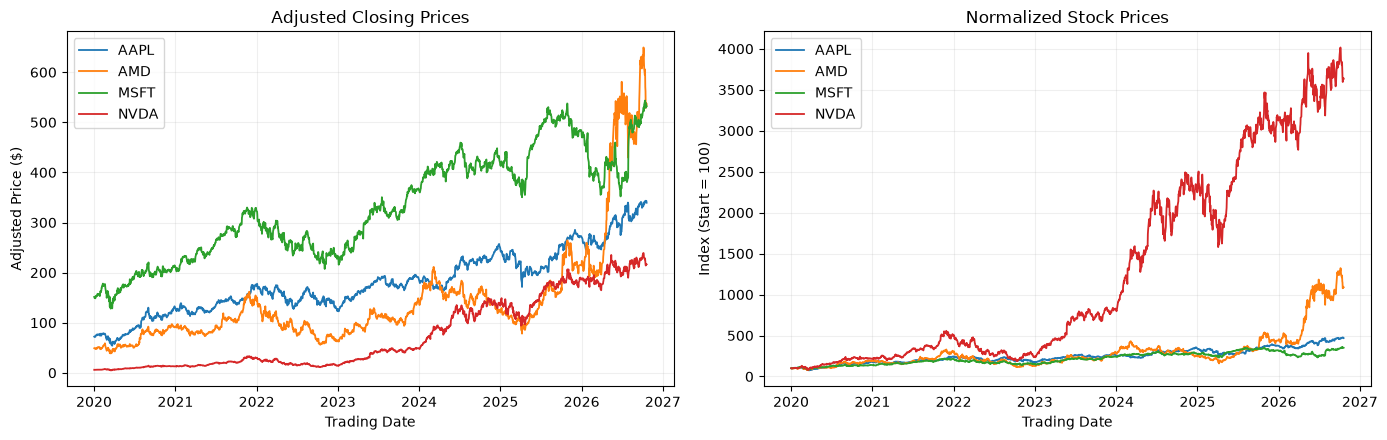

In [8]:
# Select representative stocks for visual comparison (from parameters)
selected_tickers = EDA_TICKERS

# Filter cleaned observations and keep chronological order
# Actual historical price series adjusted (e.g. stock splits    )
price_df = (
    clean_df.loc[clean_df[TICKER_COL].isin(selected_tickers)]
    .sort_values([TICKER_COL, DATE_COL])
    .copy()
)

# Normalize/rescale each stock's price to 100 at its first available observation
# This compares relative price movements instead of different dollar price levels
# Norm. P = (Adj P / First Adj P) * 100
price_df["Normalized_Price"] = (
    price_df[PRICE_COL]
    / price_df.groupby(TICKER_COL)[PRICE_COL].transform("first")
    * 100
)

# two charts side by side for easier comparison
fig, axes = plt.subplots(1, 2, figsize = (14, 4.5))

for ticker, group in price_df.groupby(TICKER_COL):

    # Left: actual adjusted closing prices
    axes[0].plot(
        group[DATE_COL], group[PRICE_COL],
        label = ticker, linewidth = 1.3
    )

    # Right: normalized prices, with each stock starting at 100
    axes[1].plot(
        group[DATE_COL], group["Normalized_Price"],
        label = ticker, linewidth = 1.3
    )

# Apply consistent formatting to both charts
axes[0].set_title("Adjusted Closing Prices")
axes[0].set_ylabel("Adjusted Price ($)")

axes[1].set_title("Normalized Stock Prices")
axes[1].set_ylabel("Index (Start = 100)")

for ax in axes:
    ax.set_xlabel("Trading Date")
    ax.grid(alpha = 0.2)
    ax.legend()

plt.tight_layout()
plt.show()

## 3.3 - Return Distribution
- identifying skewness, outliers / extreme returns
- calculating log returns from prices when available, or using existing returns after verifying their definition and units.
    - log is convenient for time-series analysis. (e.g. sum of 5 consecutive daily log returns = log return over the entire 5-day period.)
    - using `Trading_Day_Index` to avoid calculating returns across missing trading observations.
    - currently treats an existing return series as log returns, if dataset contains simple decimal returns, must convert them first:
    
returns_df["Daily_Log_Return"] = np.log(
    returns_df[PRICE_COL] / previous_price
)

,Daily Return (%)
count,843127.0000
mean,0.0437
std,2.4052
min,-77.3593
25%,-0.9889
50%,0.0685
75%,1.1112
max,101.8737


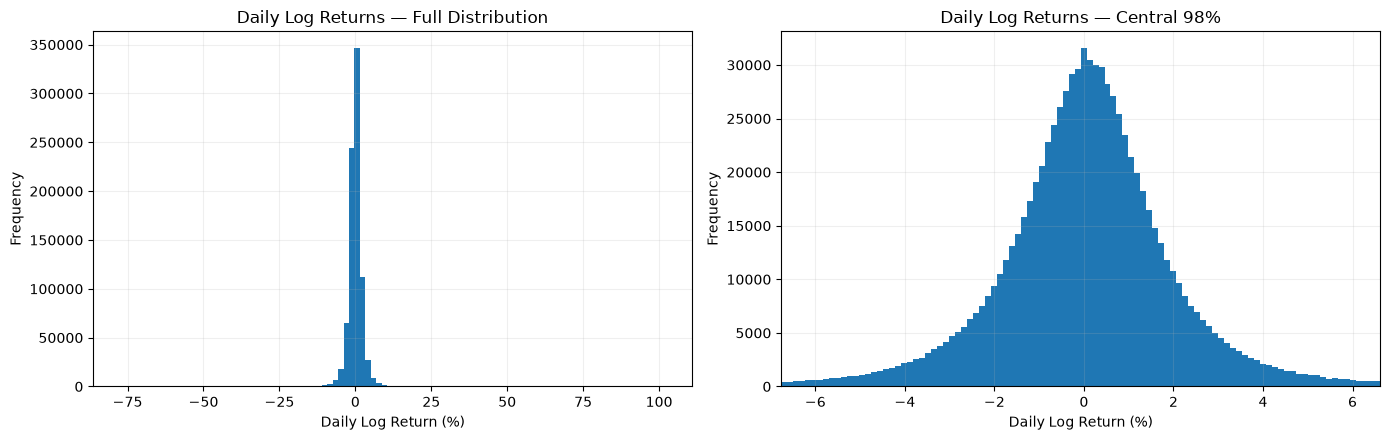

In [9]:
# Prepare daily returns using all cleaned stock observations
returns_df = clean_df.copy()

# Identify each stock's previous adjusted price and trading-day position
previous_price = returns_df.groupby(TICKER_COL)[PRICE_COL].shift(1)                             # groupby ensures returns are calculated within each stock, not across tickers
previous_day = returns_df.groupby(TICKER_COL)["Trading_Day_Index"].shift(1)

# Calculate daily log returns only for consecutive trading observations
# Missing sessions are excluded to avoid treating multi-day changes as daily returns
consecutive = (returns_df["Trading_Day_Index"] - previous_day == 1)                             # consecutive, confirms the previous observation belongs to the immediately preceding trading session

returns_df["Daily_Log_Return"] = np.where(
    consecutive,
    np.log(returns_df[PRICE_COL] / previous_price),                                             # calculates the daily log return
    np.nan
)

# Collect valid daily returns across the full stock universe
daily_returns = returns_df["Daily_Log_Return"].dropna()                                         # removes the first return per stock and returns spanning missing observations

# Summarize the distribution in percentage terms
return_summary = (daily_returns * 100).describe().to_frame("Daily Return (%)")

# Create side-by-side views of the distribution and its extreme observations
fig, axes = plt.subplots(1, 2, figsize = (14, 4.5))

# Left: full return distribution, including extreme market movements
axes[0].hist(daily_returns * 100, bins = 100)
axes[0].set_title("Daily Log Returns — Full Distribution")
axes[0].set_xlabel("Daily Log Return (%)")
axes[0].set_ylabel("Frequency")

# Right: zoom into the central 98% to reveal the distribution's typical shape
lower, upper = daily_returns.quantile([0.01, 0.99])                                             # identifies the 1st and 99th percentiles of daily returns

central_returns = daily_returns[
    daily_returns.between(lower, upper)                                                         # filters out extreme observations/returns (for visualization only)
]

# Plot the central 98% without creating artificial boundary spikes                              # more visually appealing bellshape curve
axes[1].hist(central_returns * 100, bins = 100)
axes[1].set_xlim(lower * 100, upper * 100)
axes[1].set_title("Daily Log Returns — Central 98%")
axes[1].set_xlabel("Daily Log Return (%)")
axes[1].set_ylabel("Frequency")

# Apply consistent formatting to both charts
for ax in axes:
    ax.grid(alpha = 0.2)

plt.tight_layout()
display(return_summary.round(4))
plt.show()

## 3.4 Historical Volatilty
- examining rolling volatility over 5, 10, and 20 trading days.
    - calculates/visualizes rolling volatility across short-and medium-term historical windows.

Distinction/Limitation:
- Historical rolling volatility = previous five observed returns, including today's return.
    - uses past data
    - can act as predictor
- Future five-day variance target = next five returns, which are unknown at prediction time.
    - does not uses past data
    - uses future data for training labels
    - can act as target

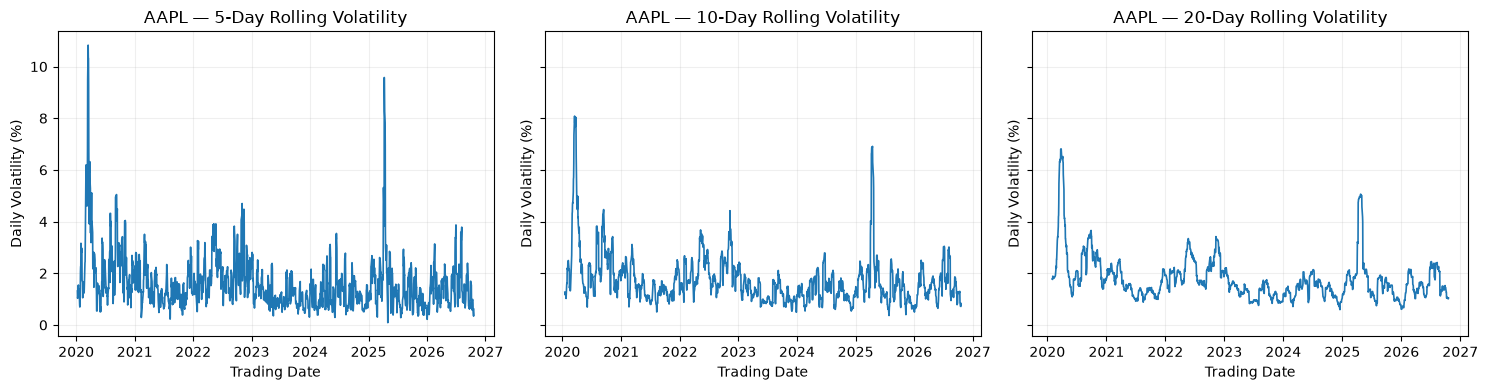

,5-Day,10-Day,20-Day
Observations,841111.000,838591.000,833557.000
Mean (%),1.893,1.986,2.049
Median (%),1.507,1.628,1.715
Std. of Estimates (pp),1.506,1.375,1.274
Maximum (%),50.044,34.709,24.375


In [10]:
# Verify that daily returns were calculated in 3.3
if "returns_df" not in globals() or "Daily_Log_Return" not in returns_df.columns:
    raise ValueError("Run 3.3 Return Distribution before calculating volatility.")

# Preserve the return dataset and chronological stock-level ordering
volatility_df = (
    returns_df.copy()
    .sort_values([TICKER_COL, DATE_COL])
)

# Calculate rolling standard deviation independently for each stock
# min_periods requires a complete window of valid daily returns
for window in RW:
    volatility_df[f"Volatility_{window}D"] = (
        volatility_df.groupby(TICKER_COL)["Daily_Log_Return"]               # prevents returns from different stocks being combined.
        .transform(lambda returns: returns.rolling(                         # calculates historical daily-return volatility using the most recent 5, 10, or 20 observations.
            window = window,
            min_periods = window                                            # requires enough valid returns before reporting volatility.
        ).std())
    )

# Select one stock for a readable comparison of rolling windows
selected_ticker = EDA_TICKERS[0]

plot_df = volatility_df.loc[
    volatility_df[TICKER_COL] == selected_ticker
]

# Display each rolling window in a separate chart
fig, axes = plt.subplots(1, len(RW), figsize = (15, 4), sharey = True)

for ax, window in zip(axes, RW):
    ax.plot(
        plot_df[DATE_COL],
        plot_df[f"Volatility_{window}D"] * 100,
        linewidth = 1.2
    )

    ax.set_title(f"{selected_ticker} — {window}-Day Rolling Volatility")
    ax.set_xlabel("Trading Date")
    ax.set_ylabel("Daily Volatility (%)")
    ax.grid(alpha = 0.2)

plt.tight_layout()
plt.show()

# Summarize historical daily volatility across all stocks
# Values are percentages; columns represent different estimation windows
volatility_cols = [f"Volatility_{window}D" for window in RW]

volatility_summary = (
    (volatility_df[volatility_cols] * 100)
    .agg(["count", "mean", "median", "std", "max"])
    .round(3)
)

# Use readable window names and statistic labels
volatility_summary.columns = [f"{window}-Day" for window in RW]
volatility_summary.index = [
    "Observations", "Mean (%)", "Median (%)",
    "Std. of Estimates (pp)", "Maximum (%)"
]

display(volatility_summary)

## 3.5 Patterns
- examining whether historical returns and volatility exhibit persistence over time.
- using autocorrelation, which measures the relationship between a variable and its own previous observations.

| Analysis | Testing | Usefulness |
|---|---|---|
|Return autocorrelation|Do past returns relate to subsequent returns?|Potential predictability of price movements|
|Squared-return autocorrelation|Do large market movements tend to follow other large movements?|Potential volatility clustering|

Lag,Return_ACF,Squared_Return_ACF,Stocks
1,-0.049300,0.198500,502
2,0.037000,0.215400,502
5,0.021500,0.150500,502
10,-0.016200,0.098300,502
20,-0.000000,0.047700,502


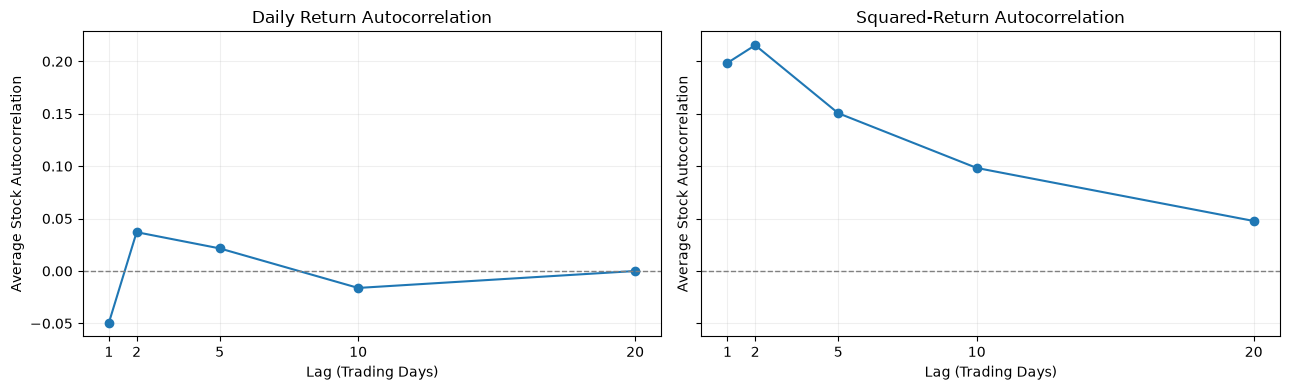

In [11]:
# Temporal Analysis
LAGS = [1, 2, 5, 10, 20]  # Number of trading sessions separating observations

# Use prepared daily returns and preserve stock-level chronological order
temporal_df = (
    returns_df.copy()
    .sort_values([TICKER_COL, DATE_COL])
)

# Square returns to measure movement magnitude regardless of direction
# Large positive and negative returns both produce large squared values
temporal_df["Squared_Return"] = temporal_df["Daily_Log_Return"] ** 2

# Store the average stock-level autocorrelation for each trading-day lag
autocorr_results = []

for lag in LAGS:

    # Retrieve earlier observations from the same stock
    previous_day = temporal_df.groupby(TICKER_COL)["Trading_Day_Index"].shift(lag)

    # Ensure observations are separated by exactly the requested number of sessions
    # This prevents missing-price gaps from changing the meaning of a lag
    valid_lag = (
        temporal_df["Trading_Day_Index"] - previous_day == lag
    )

    # Compare current values against their own stock's lagged values
    stock_correlations = []

    for ticker, group in temporal_df.groupby(TICKER_COL):

        # Identify valid lag pairs for this stock
        mask = valid_lag.loc[group.index]

        # Calculate lagged returns and squared returns
        lagged_returns = group["Daily_Log_Return"].shift(lag)
        lagged_squared = group["Squared_Return"].shift(lag)

        # Retain only valid consecutive-session comparisons
        current_returns = group["Daily_Log_Return"].where(mask)
        current_squared = group["Squared_Return"].where(mask)

        # Require enough valid pairs for meaningful stock-level correlations
        if current_returns.notna().sum() >= 30:
            stock_correlations.append({
                "Return_ACF": current_returns.corr(lagged_returns),
                "Squared_Return_ACF": current_squared.corr(lagged_squared)
            })

    # Average the correlations across eligible stocks
    stock_acf = pd.DataFrame(stock_correlations)

    autocorr_results.append({
        "Lag": lag,
        "Return_ACF": stock_acf["Return_ACF"].mean(),
        "Squared_Return_ACF": stock_acf["Squared_Return_ACF"].mean(),
        "Stocks": len(stock_acf)
    })

# Summarize stock-level temporal patterns across the S&P 500 universe
autocorr_df = pd.DataFrame(autocorr_results)

display(autocorr_df.round(4).style.hide(axis = "index"))

# Visualize return and squared-return autocorrelation side by side
fig, axes = plt.subplots(1, 2, figsize = (13, 4), sharey = True)

for ax, column, title in zip(
    axes,
    ["Return_ACF", "Squared_Return_ACF"],
    ["Daily Return Autocorrelation", "Squared-Return Autocorrelation"]
):
    ax.plot(
        autocorr_df["Lag"],
        autocorr_df[column],
        marker = "o",
        linewidth = 1.5
    )

    # Zero indicates no measured linear autocorrelation
    ax.axhline(0, color = "gray", linestyle = "--", linewidth = 1)

    ax.set_title(title)
    ax.set_xlabel("Lag (Trading Days)")
    ax.set_ylabel("Average Stock Autocorrelation")
    ax.set_xticks(LAGS)
    ax.grid(alpha = 0.2)

plt.tight_layout()
plt.show()

What to look fo:
- Daily returns may exhibit weak autocorrelation, while squared returns may exhibit positive autocorrelation that gradually declines across longer lags.
    - such pattern would support using historical volatility as a predictor in our regression models.
    - but, autocorr alone does not establish statistical significance / guarantee improved forecasting performance.

## 3.6 - EDA Summary
- Summarize return behavior, historical volatility, and temporal persistence before feature engineering.


**Objective:** Consolidate the main findings from exploratory analysis and identify implications for five-day volatility forecasting.

| Analysis | Key Finding | Modeling Implication |
|---|---|---|
| Dataset overview | 503 stocks, 843,631 clean stock-date observations, 1,709 trading dates | Sufficient panel coverage for an initial supervised learning framework |
| Price trends | Stocks exhibit different price levels and historical growth patterns | Use returns rather than raw price levels as primary risk measures |
| Return distribution | Daily returns are concentrated near zero with substantial extreme observations | Account for volatility spikes and heavy-tailed return behavior |
| Rolling volatility | Shorter windows respond rapidly; longer windows produce smoother estimates | Include multiple historical volatility windows as predictors |
| Return autocorrelation | Average correlations are relatively close to zero | Return direction is not the primary forecasting objective |
| Squared-return autocorrelation | Positive correlations decline from approximately 0.20 at short lags to 0.05 at lag 20 | Historical volatility contains potentially useful predictive information |

**Overall conclusion**

The EDA supports forecasting future volatility rather than stock-price direction. Historical volatility varies over time and exhibits persistence, motivating supervised regression models using lagged returns, rolling volatility, and trading activity.

**Limitations**

- Results are descriptive and do not establish out-of-sample forecasting performance.
- Extreme returns may reflect market shocks or security-specific events and require further validation.
- Stocks have unequal historical coverage, particularly recent listings.
- The historical universe uses currently selected index constituents, introducing potential survivorship bias.

**Next:** Construct historical predictors (X) and the future five-trading-day realized variance target (y), ensuring no future information enters the predictors.


### 3.6.1 - EDA Summary [Plots]


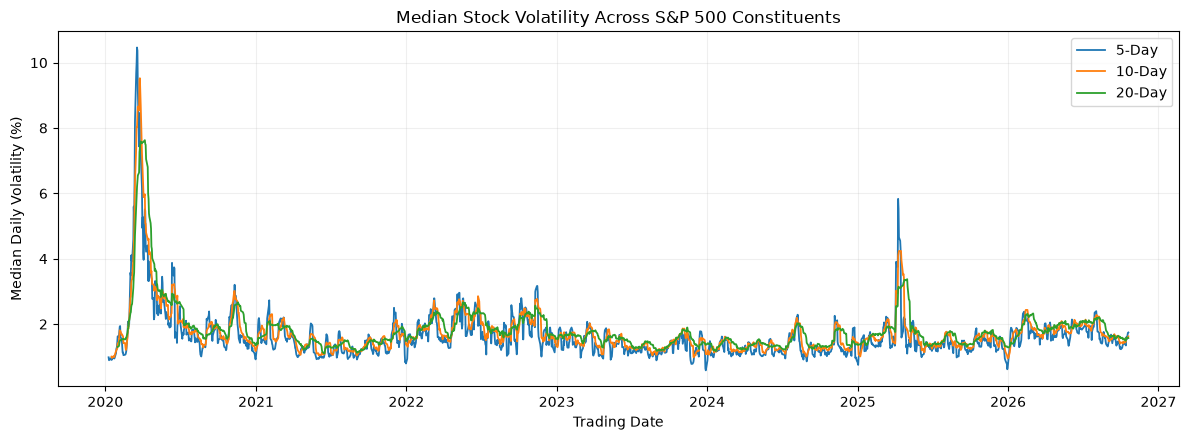

In [12]:
# Calculate the cross-sectional median rolling volatility for each trading date
# This summarizes individual-stock volatility across the available S&P 500 constituents
volatility_cols = [f"Volatility_{window}D" for window in RW]

market_volatility = (
    volatility_df.groupby(DATE_COL)[volatility_cols]
    .median()
    .mul(100)
)

# Plot market-wide volatility estimates using the same daily percentage scale
fig, ax = plt.subplots(figsize = (12, 4.5))

for window in RW:
    ax.plot(
        market_volatility.index,
        market_volatility[f"Volatility_{window}D"],
        label = f"{window}-Day",
        linewidth = 1.3
    )

ax.set_title("Median Stock Volatility Across S&P 500 Constituents")
ax.set_xlabel("Trading Date")
ax.set_ylabel("Median Daily Volatility (%)")
ax.grid(alpha = 0.2)
ax.legend()

plt.tight_layout()
plt.show()

Findings (if interested):
- 1st peak obvious = COVID
- 2nd peak around April 2025 was the tariff shock.

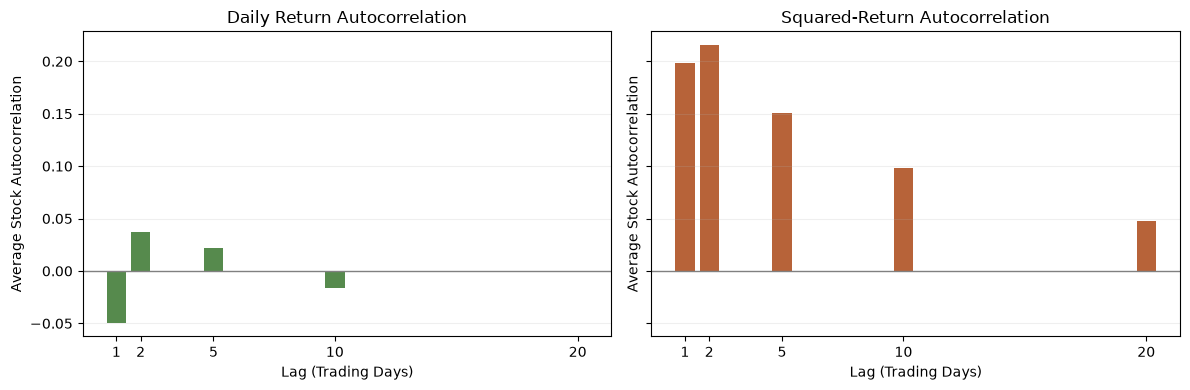

In [13]:
# Compare stock-level return and squared-return autocorrelation side by side
# Both charts share the same vertical scale for direct comparison
fig, axes = plt.subplots(1, 2, figsize = (12, 4), sharey = True)

# Daily return autocorrelation: persistence of signed returns
axes[0].bar(
    autocorr_df["Lag"],
    autocorr_df["Return_ACF"],
    color = "#568A4D",
    width = 0.8
)
axes[0].set_title("Daily Return Autocorrelation")

# Squared-return autocorrelation: persistence of movement magnitude
axes[1].bar(
    autocorr_df["Lag"],
    autocorr_df["Squared_Return_ACF"],
    color = "#B76339",
    width = 0.8
)
axes[1].set_title("Squared-Return Autocorrelation")

# Apply consistent formatting to both charts
for ax in axes:
    ax.axhline(0, color = "gray", linewidth = 1)
    ax.set_xlabel("Lag (Trading Days)")
    ax.set_ylabel("Average Stock Autocorrelation")
    ax.set_xticks(LAGS)
    ax.grid(axis = "y", alpha = 0.2)

plt.tight_layout()
plt.show()

In [14]:
# EDA Statistical Summary #

# Verify that EDA results are available
if DATASET is None:
    print("Dataset pending — EDA summary skipped.")

elif (
    "volatility_df" not in globals()
    or "autocorr_df" not in globals()
):
    print("EDA results unavailable — review previous cells.")

else:
    # Summarize daily return characteristics
    daily_returns = volatility_df["Daily_Log_Return"].dropna()                              # excludes missing returns from summary calculations

    # Collect descriptive and temporal statistics
    eda_summary = pd.DataFrame({
        "Metric": [
            "Stocks",
            "Valid Daily Returns",
            "Mean Daily Return (%)",
            "Daily Return Std (%)",
            "Minimum Daily Return (%)",
            "Maximum Daily Return (%)",
            "Mean 5-Day Rolling Volatility (%)",
            "Mean 20-Day Rolling Volatility (%)",
            "Return ACF (Lag 1)",
            "Squared Return ACF (Lag 1)"
        ],
        "Value": [
            returns_df[TICKER_COL].nunique(),                                               # unique stocks, not ticker names
            daily_returns.count(),
            daily_returns.mean() * 100,                                                     # average observed value
            daily_returns.std() * 100,                                                      # dispersion
            daily_returns.min() * 100,                                                      # extreme observed returns
            daily_returns.max() * 100,
            volatility_df["Volatility_5D"].mean() * 100,
            volatility_df["Volatility_20D"].mean() * 100,
            autocorr_df.loc[autocorr_df["Lag"] == 1, "Return_ACF"].iloc[0],                 # .loc retrieves the autocorrelation calculated at lag 1
            autocorr_df.loc[autocorr_df["Lag"] == 1, "Squared_Return_ACF"].iloc[0]          # .iloc extracts the first matching value
        ]
    })

    # Display observation counts as integers and statistical measures to four decimals
    eda_summary["Value"] = [
        f"{value:,.0f}" if metric in ["Stocks", "Valid Daily Returns"] else f"{value:.4f}"
        for metric, value in zip(eda_summary["Metric"], eda_summary["Value"])               # "zip()"generates each pair on demand as it iterate.
    ]

    display(eda_summary.style.hide(axis="index"))


Metric,Value
Stocks,503
Valid Daily Returns,"843,127"
Mean Daily Return (%),0.0437
Daily Return Std (%),2.4052
Minimum Daily Return (%),-77.3593
Maximum Daily Return (%),101.8737
Mean 5-Day Rolling Volatility (%),1.8933
Mean 20-Day Rolling Volatility (%),2.0491
Return ACF (Lag 1),-0.0493
Squared Return ACF (Lag 1),0.1985


# ============================================================
# PART 4 - Target Construction & Feature Engineering
# ============================================================

## 4.1 - Standardized Data Schema
- establishing the dataset that will be used to construct predictors and targets.

In [15]:
# Prepare the stock-date dataset for feature and target engineering
# Preserve the original cleaned data and previously calculated log returns
model_df = (
    returns_df.copy()
    .sort_values([TICKER_COL, DATE_COL])
    .reset_index(drop = True)
)

# Verify the required columns before constructing features and targets
required_cols = [
    DATE_COL,
    TICKER_COL,
    PRICE_COL,
    "Trading_Day_Index",
    "Daily_Log_Return"                                                                  # expect large value as output, since 1st observation for each stock has no previous price.
]

missing_cols = [col for col in required_cols if col not in model_df.columns]

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

duplicates = model_df.duplicated(subset = [TICKER_COL, DATE_COL]).sum()                   # comfirms that each stock has at most one observation per trading date

if duplicates:
    raise ValueError(f"Duplicate stock-date observations: {duplicates}")

# Summarize the modeling schema without displaying hundreds of thousands of rows
schema_summary = pd.DataFrame({
    "Column": model_df.columns,
    "Data Type": model_df.dtypes.astype(str).values,                                    # fyi, datetime64[s] prefix is seconds.
    "Missing Values": model_df.isna().sum().values
})

display(schema_summary.style.hide(axis = "index"))

print(f"Observations: {len(model_df):,}")
print(f"Stocks: {model_df[TICKER_COL].nunique():,}")
print(f"Trading dates: {model_df[DATE_COL].nunique():,}")

Column,Data Type,Missing Values
Date,datetime64[s],0
Ticker,str,0
Open,float64,0
High,float64,0
Low,float64,0
Adjusted_Close,float64,0
Volume,float64,0
Trading_Day_Index,int64,0
Daily_Log_Return,float64,504


Observations: 843,631
Stocks: 503
Trading dates: 1,709


## 4.2 - Target Construction
- constructing the variable our machine learning algorithms to predict how volatile a stock will be over the next five trading days.
    - on each stock and each date, need to calculate the actual future variance (becomes our target (y) when training the model)
- using model_df from 4.1 and existing HZ = 5 and TARGET = "Future_Variance_5D" parameters.

In [16]:
# Preserve stock-level chronological ordering established in 4.1
model_df = model_df.sort_values(
    [TICKER_COL, DATE_COL]
).reset_index(drop = True)

# Group observations by stock to prevent mixing returns across tickers
stock_groups = model_df.groupby(TICKER_COL)                                         # ensures each stock's future returns are calculated separately

# Calculate the next HZ daily squared returns for each stock
future_squared_returns = []

for h in range(1, HZ + 1):                                                          # loop gathers 5 future returns, squares each, and stores them temporarily in a list.
    future_return = stock_groups["Daily_Log_Return"].shift(-h)                      # h means how many trading sessions ahead we're looking. (- shift is pandas, brings the next observation into the current row)
    future_squared_returns.append(future_return ** 2)                               # removes direction and emphasizes large price movements

# Combine future squared returns
# One future five-day realized variance value per eligible stock-date observation.
future_variance = pd.concat(future_squared_returns, axis = 1)                       # pd.concat, concatenate/side-b-side objects along a particular axis.

model_df[TARGET] = future_variance.sum(
    axis = 1,
    min_count = HZ                                                                  # requires all five values to exist
)

# Verify that the target ends exactly HZ trading sessions after the current date
# Prevents missing-price gaps from producing an incorrect forecast horizon
future_day = stock_groups["Trading_Day_Index"].shift(-HZ)

valid_horizon = (
    future_day - model_df["Trading_Day_Index"] == HZ
)

model_df.loc[~valid_horizon, TARGET] = np.nan                                       # for rows where the forecast horizon is invalid, marks target as missing

# Summarize target availability without removing observations "prematurely"
target_summary = pd.DataFrame({
    "Metric": [
        "Observations",                                                             # total stock-date rows currently in model_df
        "Valid Targets",                                                            # only those with five valid future returns
        "Missing Targets",                                                          # those without a complete five-day future target = ( Observations - Valid Targets)
        "Stocks",                                                                   # same as observation, but for tickers
        "Forecast Horizon"                                                          # del, removed from output
    ],
    "Value": [
        len(model_df),
        model_df[TARGET].notna().sum(),
        model_df[TARGET].isna().sum(),
        model_df[TICKER_COL].nunique(),
        HZ
    ]
})

# Summarize target availability
target_summary = pd.DataFrame({
    "Metric": ["Observations", "Valid Targets", "Missing Targets", "Stocks"],
    "Value": [
        len(model_df),
        model_df[TARGET].notna().sum(),
        model_df[TARGET].isna().sum(),
        model_df[TICKER_COL].nunique()
    ]
})

# Display counts as whole numbers with thousands separators
target_summary["Value"] = target_summary["Value"].map(lambda x: f"{x:,}")

display(target_summary.style.hide(axis = "index"))

Metric,Value
Observations,"843,631"
Valid Targets,"841,111"
Missing Targets,"2,520"
Stocks,503


## 4.3 - Historical Feature Engineering
- Defines lagged returns and rolling historical variance
- Construct the predictors (X) that our models will use to forecast future five-day realized variance (y).
    - Overall financial time-series predictors must respect chronological order.
        - We cannot use infos from tmr to predict tmr's volatility.
- uses existing parameters RW, LAGS (from 3.5), TICKER_COL, and DATE_COL
    - uses Trading_Day_Index to avoid treating missing sessions as valid consecutive observations.

| Feature | Description | Purpose |
|---|---|---|
| Current Return | Today's daily log return | Recent price movement |
| Squared Return | Today's return squared | Magnitude of recent movement |
| Lagged Returns | Returns from earlier trading sessions | Historical return patterns |
| Rolling Volatility | Standard deviation over 5, 10, and 20 days | Recent volatility conditions |
| Log Volume | Log-transformed trading volume | Trading activity |
| Relative Volume | Current volume divided by recent average volume | Unusual trading activity |  

In [17]:
# Preserve chronological order within each stock
model_df = model_df.sort_values(
    [TICKER_COL, DATE_COL]
).reset_index(drop = True)

stock_groups = model_df.groupby(TICKER_COL)

# Track engineered predictor names for later modeling and validation
feature_cols = []

# 1. Current return and squared return
# Both are known after today's market close
model_df["Return_0D"] = model_df["Daily_Log_Return"]                                                # stock declined (captures direction)
model_df["Squared_Return_0D"] = model_df["Daily_Log_Return"] ** 2                                   # magnitude of movement, regardless of direction

feature_cols.extend(["Return_0D", "Squared_Return_0D"])


# 2. Historical lagged returns
# shift(lag) retrieves past returns; positive shifts never access future data
for lag in LAGS:

    previous_return = stock_groups["Daily_Log_Return"].shift(lag)                                   # gets returns from several earlier trading sessions. (e.g 1D = yesterday |2D = two trading sessions ago | 5D = ~week ...)
    previous_day = stock_groups["Trading_Day_Index"].shift(lag)                                     # shift(lag) = past direction vs shift(-h) = future dir. (from 4.2) | Trading_Day_Index to make sure the lag represents the right nb of trading sessions.

    # Require the lag to represent the correct number of trading sessions
    valid_lag = (
        model_df["Trading_Day_Index"] - previous_day == lag
    )

    feature_name = f"Return_Lag_{lag}D"

    model_df[feature_name] = previous_return.where(valid_lag)                                       # keeps lagged returns ONLY when the trading-session distance is correct
    feature_cols.append(feature_name)


# 3. Historical rolling volatility
# Calculate standard deviation using only current and previous returns_df                           # same concept as 3.4, but now the results become predictors.
for window in RW:

    feature_name = f"Volatility_{window}D"

    model_df[feature_name] = (
        stock_groups["Daily_Log_Return"]
        .transform(
            lambda x: x.rolling(                                                                    # estimates historical daily volatility
                window = window,
                min_periods = window
            ).std()
        )
    )

    feature_cols.append(feature_name)


# 4. Trading volume features
# log1p reduces the influence of extremely large trading-volume values
model_df["Log_Volume"] = np.log1p(model_df["Volume"])                                               # measures the number of shares traded during a session, & compresses scale of trading volume (since without, stocks can have large diff trading volumes.)

# Compare current volume with the stock's recent average
# Relative volume above 1 indicates higher-than-average activity
volume_window = max(RW)

average_volume = (
    stock_groups["Volume"]
    .transform(
        lambda x: x.rolling(
            window = volume_window,
            min_periods = volume_window
        ).mean()
    )
)

model_df["Relative_Volume"] = (
    model_df["Volume"] / average_volume.replace(0, np.nan)
)

feature_cols.extend(["Log_Volume", "Relative_Volume"])                                              # ompares today's trading volume with the stock's own recent average (let us know whether today's trading activity was unusual for that stock)


# Summarize the engineered predictors and their availability
feature_summary = pd.DataFrame({
    "Feature": feature_cols,                                                                        # predictor name.
    "Missing": model_df[feature_cols].isna().sum().to_numpy(),                                      # nb of observations without valid value.
    "Available (%)": (                                                                              # % of stock-date rows with that predictor available.
        model_df[feature_cols].notna().mean().mul(100).round(2).to_numpy()                          # fixed static type-checking warning with .mul()
    )
})

display(feature_summary.style.hide(axis="index"))

print(f"Candidate predictors: {len(feature_cols)}")

Feature,Missing,Available (%)
Return_0D,504,99.940000
Squared_Return_0D,504,99.940000
Return_Lag_1D,1008,99.880000
Return_Lag_2D,1512,99.820000
Return_Lag_5D,3024,99.640000
Return_Lag_10D,5544,99.340000
Return_Lag_20D,10577,98.750000
Volatility_5D,2520,99.700000
Volatility_10D,5040,99.400000
Volatility_20D,10074,98.810000


Candidate predictors: 12


## 4.4 - Feature Availability & Leakage
- before training, we need to confirm that these variables are usable and correctly aligned.
    - verifies that predictors use no future information

In [18]:
# Preserve chronological order and group observations by stock
model_df = model_df.sort_values(
    [TICKER_COL, DATE_COL]
).reset_index(drop = True)

stock_groups = model_df.groupby(TICKER_COL)

# 1. Validate historical continuity
# A rolling window is valid only if its observations cover consecutive trading sessions
for window in RW:

    feature_name = f"Volatility_{window}D"

    # The oldest observation in a window of W returns is W-1 rows behind today
    oldest_day = stock_groups["Trading_Day_Index"].shift(window - 1)                                                # historical continuity

    # Require exactly W-1 trading-session intervals between endpoints                                               # confirms that the rows span the expected number of trading sessions.
    valid_window = (
        model_df["Trading_Day_Index"] - oldest_day == window - 1
    )

    # Mark rolling volatility as missing if the window crosses a missing session
    model_df.loc[~valid_window, feature_name] = np.nan


# 2. Validate lagged-return continuity
# A lagged return must correspond to the intended previous trading session
for lag in LAGS:

    feature_name = f"Return_Lag_{lag}D"

    previous_day = stock_groups["Trading_Day_Index"].shift(lag)

    valid_lag = (
        model_df["Trading_Day_Index"] - previous_day == lag
    )

    model_df.loc[~valid_lag, feature_name] = np.nan


# 3. Validate relative-volume window continuity
# Use the same historical window previously defined (4.3)
volume_window = max(RW)

oldest_volume_day = stock_groups["Trading_Day_Index"].shift(
    volume_window - 1
)

valid_volume_window = (
    model_df["Trading_Day_Index"] - oldest_volume_day == volume_window - 1
)

model_df.loc[~valid_volume_window, "Relative_Volume"] = np.nan


# 4. Check feature and target availability
# A row is eligible only when all predictors and its future target are available
valid_features = model_df[feature_cols].notna().all(axis = 1)                                                   # .notna() checks for nonmissing values, while .all() requires every selected feature in the row to pass.
valid_target = model_df[TARGET].notna()                                                                         # target completness, whether the next 5 trading sessions were available for calculating realized variance.
valid_rows = valid_features & valid_target                                                                      # model-ready observations, must have complete predictors AND target

# Keep the complete original dataset; create a separate dataset for modeling
training_df = model_df.loc[valid_rows].copy()


# 5. Summarize observation availability
availability_summary = pd.DataFrame({
    "Metric": [
        "Total Observations",
        "Complete Features",
        "Valid Targets",
        "Model-Ready Observations",
        "Excluded Observations",
        "Model-Ready Stocks"
    ],
    "Value": [
        len(model_df),
        valid_features.sum(),
        valid_target.sum(),
        len(training_df),
        len(model_df) - len(training_df),
        training_df[TICKER_COL].nunique()
    ]
})

# Display counts as whole numbers
availability_summary["Value"] = availability_summary["Value"].map(
    lambda x: f"{x:,}"
)

display(availability_summary.style.hide(axis = "index"))

Metric,Value
Total Observations,"843,631"
Complete Features,"833,054"
Valid Targets,"841,111"
Model-Ready Observations,"830,539"
Excluded Observations,"13,092"
Model-Ready Stocks,502


## 4.5 - Feature Engineering Summary
- consolidating the engineered predictors (Xs), forecasting target (Y), and model-ready dataset before proceeding to model training.
- reuses training_df, feature_cols, and TARGET from the previous sections. It does not modify the data.

In [19]:
# Summarize the final model-ready dataset
model_summary = pd.DataFrame({
    "Metric": [
        "Model-Ready Observations",
        "Stocks",
        "Trading Dates",
        "Predictors",
        "Target",
        "Start Date",
        "End Date"
    ],
    "Value": [
        f"{len(training_df):,}",
        f"{training_df[TICKER_COL].nunique():,}",
        f"{training_df[DATE_COL].nunique():,}",
        len(feature_cols),
        TARGET,
        str(training_df[DATE_COL].min().date()),
        str(training_df[DATE_COL].max().date())
    ]
})

# Display dataset coverage without the default pandas index
display(model_summary.style.hide(axis = "index"))

# Summarize the engineered predictors and their definitions
feature_definitions = {
    "Return_0D": "Current daily log return",
    "Squared_Return_0D": "Current daily log return squared",
    "Log_Volume": "Log-transformed daily trading volume",
    "Relative_Volume": "Current volume relative to its historical average"
}

# Add descriptions for parameterized lagged returns and volatility windows
for lag in LAGS:
    feature_definitions[f"Return_Lag_{lag}D"] = (
        f"Daily log return {lag} trading session(s) ago"
    )

for window in RW:
    feature_definitions[f"Volatility_{window}D"] = (
        f"Rolling standard deviation of the latest {window} daily returns"
    )

feature_table = pd.DataFrame({
    "Feature": feature_cols,
    "Definition": [
        feature_definitions[feature] for feature in feature_cols                                    # from 4.3  Each engineered predictor was added to this list.
    ]
})

display(feature_table.style.hide(axis = "index"))

Metric,Value
Model-Ready Observations,"830,539"
Stocks,502
Trading Dates,"1,683"
Predictors,12
Target,Future_Variance_5D
Start Date,2020-02-03
End Date,2026-10-13


Feature,Definition
Return_0D,Current daily log return
Squared_Return_0D,Current daily log return squared
Return_Lag_1D,Daily log return 1 trading session(s) ago
Return_Lag_2D,Daily log return 2 trading session(s) ago
Return_Lag_5D,Daily log return 5 trading session(s) ago
Return_Lag_10D,Daily log return 10 trading session(s) ago
Return_Lag_20D,Daily log return 20 trading session(s) ago
Volatility_5D,Rolling standard deviation of the latest 5 daily returns
Volatility_10D,Rolling standard deviation of the latest 10 daily returns
Volatility_20D,Rolling standard deviation of the latest 20 daily returns


Interpretations:
- Return_Lag_20D, the model needs the return from 20 trading sessions earlier: calculating that earlier return itself requires a preceding closing price, the first eligible modeling observation occurs on February 3, 2020, similarly, modeling dataset ends on October 13, 2026 (since the final five trading sessions do not have complete future targets)

- This is called a warm-up period. Doesn't mean January's observations were deleted from the original data; they simply cannot serve as complete modeling rows

Example:

| Dataset | Start Date | Purpose |
|---|---|---|
|Original market data|2020-01-02|First available trading date|
|Model-ready data|2020-02-03|First date with all required historical predictors|

# ============================================================
# PART 5 - Model Development & Validation
# ============================================================

## 5.1 - Data Splitting
- Objective: dividing the model-ready dataset into training, and testing periods while preventing temporal data leakage.

- **Training:** Fit model parameters using earlier observations.
- **Testing:** Evaluate the final selected approach on the most recent, previously unseen observations.


In [20]:
# Parameters
TEST_RATIO = 0.15       # Reserve the latest 15% of dates for final testing
PURGE = HZ              # Exclude HZ (5) trading sessions before the test period (addresses problem: overlapping future returns)
CV_SPLITS = 5           # Number of walk-forward validation folds

# Chronological Data Splitting #

# Retrieve unique trading dates in chronological order
dates = np.sort(training_df[DATE_COL].unique())
n_dates = len(dates)

# Reserve the latest 15% of dates for final testing
test_start = int(n_dates * (1 - TEST_RATIO))

# Exclude the final HZ dates before testing to avoid overlapping targets
development_dates = dates[:test_start - PURGE]
test_dates = dates[test_start:]

# Assign every stock to the same chronological periods
development_df = training_df.loc[
    training_df[DATE_COL].isin(development_dates)
].copy()

test_df = training_df.loc[
    training_df[DATE_COL].isin(test_dates)
].copy()

# Verify that the development target windows end before testing begins
if (
    development_df["Trading_Day_Index"].max() + HZ
    >= test_df["Trading_Day_Index"].min()
):
    raise ValueError("Training targets overlap with the test period.")

# Summarize the resulting datasets
split_summary = pd.DataFrame({
    "Dataset": ["Development", "Testing"],
    "Observations": [len(development_df), len(test_df)],
    "Stocks": [
        development_df[TICKER_COL].nunique(),
        test_df[TICKER_COL].nunique()
    ],
    "Start Date": [
        development_df[DATE_COL].min().date(),
        test_df[DATE_COL].min().date()
    ],
    "End Date": [
        development_df[DATE_COL].max().date(),
        test_df[DATE_COL].max().date()
    ]
})

display(
    split_summary.style
    .format({"Observations": "{:,.0f}", "Stocks": "{:,.0f}"})
    .hide(axis = "index")
)

print(f"Trading dates: {n_dates:,}")
print(f"Purged sessions: {PURGE}")
print(f"Planned CV folds: {CV_SPLITS}")

Dataset,Observations,Stocks,Start Date,End Date
Development,"701,464",499,2020-02-03,2025-10-02
Testing,"126,580",502,2025-10-10,2026-10-13


Trading dates: 1,683
Purged sessions: 5
Planned CV folds: 5


## 5.2 - Baseline Model
- target from 4.2 = future five-day realized variance | baseline = same calculation, but looks backward
- reusing model_df (retains the historical returns and trading-day positions needed), and
    - align the resulting predictions with development_df and test_df from 5.1.

In [21]:
# Historical Variance Baseline #

# Sort observations chronologically within each stock
baseline_df = model_df.sort_values(
    [TICKER_COL, DATE_COL]
).copy()

stock_groups = baseline_df.groupby(TICKER_COL)

# Square daily log returns to measure movement magnitude
baseline_df["Squared_Return"] = baseline_df["Daily_Log_Return"] ** 2

# Sum the latest HZ squared returns, including today's return
# This estimates future variance using only information available at date t
baseline_df["Baseline_Variance"] = (
    stock_groups["Squared_Return"]
    .transform(
        lambda x: x.rolling(
            window = HZ,
            min_periods = HZ
        ).sum()
    )
)

# Verify that the historical window contains consecutive trading sessions
oldest_day = stock_groups["Trading_Day_Index"].shift(HZ - 1)

valid_window = (
    baseline_df["Trading_Day_Index"] - oldest_day == HZ - 1
)

# Invalidate forecasts constructed across missing trading sessions
baseline_df.loc[~valid_window, "Baseline_Variance"] = np.nan

# Retain the identifiers and forecast needed for evaluation
baseline_predictions = baseline_df[
    [TICKER_COL, DATE_COL, "Baseline_Variance"]
].copy()

# Attach the historical baseline forecast to both chronological datasets (SQL)
development_baseline = development_df.merge(                                                # .merge() similar to SQL Joins
    baseline_predictions,
    on = [TICKER_COL, DATE_COL],                                                            # matches observations using the two
    how = "left",                                                                           # left join
    validate = "one_to_one"                                                                 # brings error if either table has duplicate ticker-date keys
)

test_baseline = test_df.merge(
    baseline_predictions,
    on = [TICKER_COL, DATE_COL],
    how = "left",
    validate = "one_to_one"
)

# Verify that all eligible observations received a baseline forecast
if (
    development_baseline["Baseline_Variance"].isna().any()
    or test_baseline["Baseline_Variance"].isna().any()
):
    raise ValueError("Some model-ready observations have no baseline forecast.")

print(f"Development forecasts: {len(development_baseline):,}")
print(f"Test forecasts: {len(test_baseline):,}")

Development forecasts: 701,464
Test forecasts: 126,580


Primary Metrics:

- **MAE:** Average absolute difference between predicted and realized five-day volatility.

- **RMSE:** Similar to MAE, but penalizes larger forecasting errors more heavily.

Optional Metric — QLIKE [REMOVED]:
- evaluates variance forecasts BUT is particularly sensitive to severe underestimation of risk.
    - two diagnostics identified 79 zero historical-variance forecasts concentrated in two stocks (SW and FERG), causing extreme QLIKE losses. (large numbers)

Both metrics are expressed in volatility percentage points.

In [22]:
# Baseline Evaluation #

# Reusable evaluation function for five-day variance forecasts
def evaluate_variance(y_true, y_pred):

    # Convert inputs to numerical arrays
    actual = np.asarray(y_true, dtype=float)
    predicted = np.asarray(y_pred, dtype=float)

    # Ensure predicted variance is nonnegative
    predicted = np.maximum(predicted, 0)

    # Convert variance into five-day volatility (%)
    actual_vol = np.sqrt(actual) * 100
    predicted_vol = np.sqrt(predicted) * 100

    # Calculate forecasting errors
    errors = actual_vol - predicted_vol

    return {
        "MAE (%)": np.mean(np.abs(errors)),
        "RMSE (%)": np.sqrt(np.mean(errors ** 2))
    }

# Evaluate the baseline on the development and test periods
baseline_results = []

for name, df in [
    ("Development", development_baseline),
    ("Testing", test_baseline)
]:

    metrics = evaluate_variance(
        df[TARGET],
        df["Baseline_Variance"]
    )

    baseline_results.append({
        "Dataset": name,
        **metrics
    })

baseline_summary = pd.DataFrame(baseline_results)

display(
    baseline_summary.drop(columns = "QLIKE", errors = "ignore")
    .style
    .format({
        "MAE (%)": "{:.4f}",
        "RMSE (%)": "{:.4f}"
    })
    .hide(axis="index")
)

Dataset,MAE (%),RMSE (%)
Development,2.0123,3.2251
Testing,2.1214,3.3500


## 5.3 - Ridge Regression
- Training a regularized linear regression model to predict future five-day realized variance from historical stock-market features.
- using StandardScaler because our predictors have very different numerical scales


In [23]:
# Parameters
RIDGE_ALPHA = 1.0                                                                   # Initial regularization strength; tune later

# Create a pipeline to standardize features before fitting Ridge
# The scaler is fitted separately within each training fold to avoid leakage
ridge_pipeline = Pipeline([                                                         # combines scaling and Ridge regression
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha = RIDGE_ALPHA))
])

# Create expanding-window cross-validation splits using unique trading dates
# gap=PURGE excludes the final HZ dates from each fold's training period
cv_dates = np.sort(development_df[DATE_COL].unique())

tscv = TimeSeriesSplit(                                                             # generates five expanding-window validation folds
    n_splits = CV_SPLITS,
    gap = PURGE                                                                     # prevents overlapping target windows at each fold boundary
)

# Store fold results and predictions for later model comparison
ridge_cv_results = []
ridge_cv_predictions = []

for fold, (train_idx, valid_idx) in enumerate(tscv.split(cv_dates), start=1):

    # Translate date positions into actual training and validation dates
    fold_train_dates = cv_dates[train_idx]
    fold_valid_dates = cv_dates[valid_idx]

    # Select every stock observation belonging to those dates
    fold_train = development_df.loc[
        development_df[DATE_COL].isin(fold_train_dates)
    ]

    fold_valid = development_df.loc[
        development_df[DATE_COL].isin(fold_valid_dates)
    ]

    # Separate predictors (X) and future variance target (y)
    X_train = fold_train[feature_cols]
    Y_train = fold_train[TARGET]

    X_valid = fold_valid[feature_cols]
    Y_valid = fold_valid[TARGET]

    # Verify that training targets do not overlap the validation period
    if (
        fold_train["Trading_Day_Index"].max() + HZ
        >= fold_valid["Trading_Day_Index"].min()
    ):
        raise ValueError(f"Target overlap detected in fold {fold}.")

    # Fit scaling and regression using training observations only
    ridge_pipeline.fit(X_train, Y_train)                                            # learns scaling parameters and regression coefficients

    # Predict future five-day variance for the validation period
    predictions = ridge_pipeline.predict(X_valid)                                   # predict() forecasts variance on later, unseen observations

    # Ridge can produce negative variance; restrict forecasts to nonnegative values
    predictions = np.maximum(predictions, 0)

    # Evaluate predictions using our reusable volatility metrics
    metrics = evaluate_variance(Y_valid, predictions)                               # evaluate_variance calculates MAE and RMSE on five-day volatility

    ridge_cv_results.append({                                                       # retains forecasts for later comparison and QLIKE (removed, but retained)
        "Fold": fold,
        "Train End": fold_train[DATE_COL].max().date(),
        "Valid Start": fold_valid[DATE_COL].min().date(),
        "Valid End": fold_valid[DATE_COL].max().date(),
        **metrics
    })

    # Preserve actual and predicted variance for later evaluation, including QLIKE
    fold_predictions = fold_valid[[TICKER_COL, DATE_COL, TARGET]].copy()
    fold_predictions["Predicted_Variance"] = predictions
    fold_predictions["Fold"] = fold

    ridge_cv_predictions.append(fold_predictions)

# Convert cross-validation results into a summary table
ridge_cv_summary = pd.DataFrame(ridge_cv_results)
# Present the expanding training and validation periods more clearly
ridge_display = ridge_cv_summary.copy()

ridge_display["Training Period"] = (
    str(development_df[DATE_COL].min().date())
    + " → "
    + ridge_display["Train End"].astype(str)
)

ridge_display["Validation Period"] = (
    ridge_display["Valid Start"].astype(str)
    + " → "
    + ridge_display["Valid End"].astype(str)
)

ridge_display = ridge_display[
    ["Fold", "Training Period", "Validation Period", "MAE (%)", "RMSE (%)"]
]

display(
    ridge_display.style
    .format({"MAE (%)": "{:.4f}", "RMSE (%)": "{:.4f}"})
    .hide(axis="index")
)

# Refit Ridge using the complete development period
# The test dataset remains untouched until final evaluation
ridge_pipeline.fit(                                                                 # trains Ridge on the complete development dataset
    development_df[feature_cols],
    development_df[TARGET]
)

print("Ridge fitted on full development dataset.")

Fold,Training Period,Validation Period,MAE (%),RMSE (%)
1,2020-02-03 → 2021-01-06,2021-01-14 → 2021-12-21,2.5837,3.2218
2,2020-02-03 → 2021-12-14,2021-12-22 → 2022-11-30,2.5702,3.3464
3,2020-02-03 → 2022-11-22,2022-12-01 → 2023-11-09,2.2197,2.9570
4,2020-02-03 → 2023-11-02,2023-11-10 → 2024-10-21,2.2171,2.9874
5,2020-02-03 → 2024-10-14,2024-10-22 → 2025-10-02,2.4591,3.4678


Ridge fitted on full development dataset.


## 5.4 Random Forest Regression
- evaluating whether nonlinear relationships between historical market indicators improve five-day variance forecasts compared with Ridge Regression and the historical baseline.

In [24]:
# Parameters
RF_TREES = 100          # Number of decision trees
RF_DEPTH = 10           # Limit complexity and training time
RF_MIN_LEAF = 20        # Minimum observations in each leaf

# Initialize a nonlinear ensemble model with controlled tree complexity
rf_model = RandomForestRegressor(
    n_estimators = RF_TREES,
    max_depth = RF_DEPTH,
    min_samples_leaf = RF_MIN_LEAF,
    random_state = RS,
    n_jobs = -1
)

# Reuse the same chronological folds used for Ridge
cv_dates = np.sort(development_df[DATE_COL].unique())

tscv = TimeSeriesSplit(
    n_splits = CV_SPLITS,
    gap = PURGE
)

rf_cv_results = []
rf_cv_predictions = []

for fold, (train_idx, valid_idx) in enumerate(tscv.split(cv_dates), start=1):

    # Select historical training dates and subsequent validation dates
    fold_train_dates = cv_dates[train_idx]
    fold_valid_dates = cv_dates[valid_idx]

    fold_train = development_df.loc[
        development_df[DATE_COL].isin(fold_train_dates)
    ]

    fold_valid = development_df.loc[
        development_df[DATE_COL].isin(fold_valid_dates)
    ]

    # Separate historical predictors and future variance targets
    X_train = fold_train[feature_cols]
    Y_train = fold_train[TARGET]

    X_valid = fold_valid[feature_cols]
    Y_valid = fold_valid[TARGET]

    # Verify that future training targets do not overlap validation
    if (
        fold_train["Trading_Day_Index"].max() + HZ
        >= fold_valid["Trading_Day_Index"].min()
    ):
        raise ValueError(f"Target overlap detected in fold {fold}.")

    # Train trees using only the historical training period
    rf_model.fit(X_train, Y_train)

    # Predict future variance for the validation period
    predictions = np.maximum(rf_model.predict(X_valid), 0)

    # Evaluate forecasts on the five-day volatility scale
    metrics = evaluate_variance(Y_valid, predictions)

    rf_cv_results.append({
        "Fold": fold,
        "Train End": fold_train[DATE_COL].max().date(),
        "Valid Start": fold_valid[DATE_COL].min().date(),
        "Valid End": fold_valid[DATE_COL].max().date(),
        **metrics
    })

    # Save predictions to support later comparisons and optional QLIKE
    fold_predictions = fold_valid[
        [TICKER_COL, DATE_COL, TARGET]
    ].copy()

    fold_predictions["Predicted_Variance"] = predictions
    fold_predictions["Fold"] = fold

    rf_cv_predictions.append(fold_predictions)

# Consolidate validation results
rf_cv_summary = pd.DataFrame(rf_cv_results)

rf_cv_predictions = pd.concat(
    rf_cv_predictions,
    ignore_index = True
)

display(
    rf_cv_summary.style
    .format({"MAE (%)": "{:.4f}", "RMSE (%)": "{:.4f}"})
    .hide(axis="index")
)

print(f"Mean CV MAE: {rf_cv_summary['MAE (%)'].mean():.4f}")
print(f"Mean CV RMSE: {rf_cv_summary['RMSE (%)'].mean():.4f}")

# Refit on all development observations for eventual test evaluation
rf_model.fit(
    development_df[feature_cols],
    development_df[TARGET]
)

print("Random Forest fitted on full development dataset.")

Fold,Train End,Valid Start,Valid End,MAE (%),RMSE (%)
1,2021-01-06,2021-01-14,2021-12-21,1.8778,2.4833
2,2021-12-14,2021-12-22,2022-11-30,1.9328,2.8134
3,2022-11-22,2022-12-01,2023-11-09,1.6709,2.3689
4,2023-11-02,2023-11-10,2024-10-21,1.6823,2.4063
5,2024-10-14,2024-10-22,2025-10-02,2.0137,3.0544


Mean CV MAE: 1.8355
Mean CV RMSE: 2.6253
Random Forest fitted on full development dataset.


## 5.5 XGBoost Regression

Train XGBoost using five-fold walk-forward cross-validation with a five-trading-day gap. Evaluate forecasts using MAE and RMSE on the five-day volatility scale.

In [25]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [26]:
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit

# Use the same date-based folds as Ridge
cv_dates = np.sort(development_df[DATE_COL].unique())

tscv = TimeSeriesSplit(n_splits=CV_SPLITS, gap=PURGE)

xgb_cv_results = []
xgb_prediction_frames = []

for fold, (train_idx, valid_idx) in enumerate(tscv.split(cv_dates), start=1):
    print(f"Starting fold {fold}/{CV_SPLITS}...", flush=True)

    # Select all stocks within each chronological period
    fold_train = development_df.loc[development_df[DATE_COL].isin(cv_dates[train_idx])]

    fold_valid = development_df.loc[development_df[DATE_COL].isin(cv_dates[valid_idx])]

    # Check that training labels end before validation begins
    if (fold_train["Trading_Day_Index"].max() + HZ>= fold_valid["Trading_Day_Index"].min()):
        raise ValueError("Training targets overlap validation.")

    # Use compact arrays to reduce memory use
    X_train = fold_train[feature_cols].to_numpy(dtype=np.float32)
    X_valid = fold_valid[feature_cols].to_numpy(dtype=np.float32)

    # Express variance in squared percentage-point units
    # This improves numerical scale for tree regularization
    y_train = fold_train[TARGET].to_numpy() * 10000

    # Build a small boosting model for initial comparison
    xgb_model = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=80,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        n_jobs=2,
        random_state=RS
    )

    xgb_model.fit(X_train, y_train)

    # Convert predictions back to the original variance units
    predictions = xgb_model.predict(X_valid) / 10000
    predictions = np.maximum(predictions, 0)

    metrics = evaluate_variance(fold_valid[TARGET], predictions)

    xgb_cv_results.append({
        "Fold": fold,
        "Train End": fold_train[DATE_COL].max().date(),
        "Valid Start": fold_valid[DATE_COL].min().date(),
        "Valid End": fold_valid[DATE_COL].max().date(),
        **metrics
    })

    # Save validation predictions for comparison and error analysis
    fold_predictions = fold_valid[[TICKER_COL, DATE_COL, TARGET]].copy()

    fold_predictions["Predicted_Variance"] = predictions
    fold_predictions["Fold"] = fold
    xgb_prediction_frames.append(fold_predictions)

    print(
        f"Fold {fold} finished: "
        f"MAE={metrics['MAE (%)']:.4f}, "
        f"RMSE={metrics['RMSE (%)']:.4f}",
        flush=True
    )

# Summarize cross-validation performance
xgb_cv_summary = pd.DataFrame(xgb_cv_results)

xgb_cv_predictions = pd.concat(xgb_prediction_frames, ignore_index=True)

display(xgb_cv_summary)

display(xgb_cv_summary[["MAE (%)", "RMSE (%)"]].agg(["mean", "std"]))

# Release temporary feature arrays
del X_train, X_valid

Starting fold 1/5...
Fold 1 finished: MAE=2.2266, RMSE=2.7186
Starting fold 2/5...
Fold 2 finished: MAE=1.9846, RMSE=2.8107
Starting fold 3/5...
Fold 3 finished: MAE=1.8501, RMSE=2.5051
Starting fold 4/5...
Fold 4 finished: MAE=1.8911, RMSE=2.5621
Starting fold 5/5...
Fold 5 finished: MAE=2.1252, RMSE=3.1296


,Fold,Train End,Valid Start,Valid End,MAE (%),RMSE (%)
0,1,2021-01-06,2021-01-14,2021-12-21,2.226637,2.718594
1,2,2021-12-14,2021-12-22,2022-11-30,1.984639,2.810673
2,3,2022-11-22,2022-12-01,2023-11-09,1.850146,2.505087
3,4,2023-11-02,2023-11-10,2024-10-21,1.891150,2.562099
4,5,2024-10-14,2024-10-22,2025-10-02,2.125192,3.129624


,MAE (%),RMSE (%)
mean,2.015553,2.745215
std,0.158405,0.246960


## 5.6 Model Comparison

Compare the historical baseline, Ridge, Random Forest, and XGBoost using the same five-fold walk-forward validation and five-trading-day gap. Report mean MAE and RMSE, their standard deviations across folds, and RMSE improvement relative to the baseline. Rank the four methods by mean validation RMSE before comparing the final candidates in 5.7.


,Model,Fold,MAE (%),RMSE (%)
0,Baseline,1,1.6190,2.3457
1,Baseline,2,2.0641,3.0424
2,Baseline,3,1.7126,2.7151
3,Baseline,4,1.7219,2.8293
4,Baseline,5,2.2208,3.6798
5,Ridge,1,2.5837,3.2218
6,Ridge,2,2.5702,3.3464
7,Ridge,3,2.2197,2.9570
8,Ridge,4,2.2171,2.9874
9,Ridge,5,2.4591,3.4678


,MAE_Mean,MAE_Std,RMSE_Mean,RMSE_Std,RMSE_Improvement_vs_Baseline (%)
Model,,,,,
Random Forest,1.8355,0.1530,2.6253,0.2972,10.1696
XGBoost,2.0156,0.1584,2.7452,0.2470,6.0650
Baseline,1.8677,0.2600,2.9225,0.4930,0.0000
Ridge,2.4100,0.1814,3.1961,0.2223,-9.3628


Verified five matching folds, stock-date observations, targets, and metric units.
Lowest initial CV RMSE: Random Forest (2.6253 percentage points).


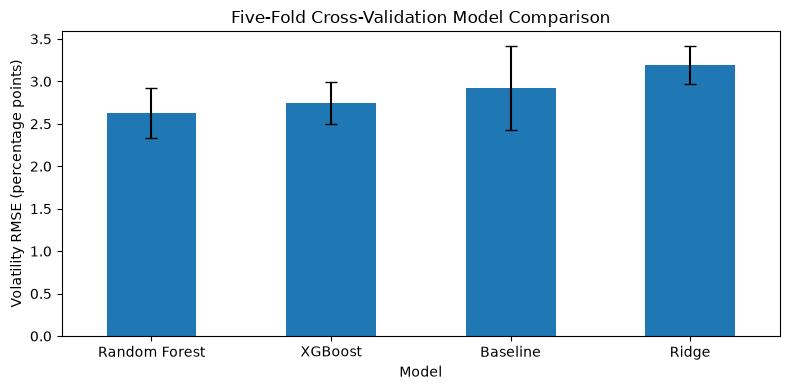

In [27]:
import hashlib
import json
from sklearn.base import clone

# Require the same five date-based folds for every comparison
if CV_SPLITS != 5:
    raise ValueError("Sections 5.6 and 5.7 require five-fold cross-validation.")
if PURGE < HZ:
    raise ValueError("The CV gap must cover the future target horizon.")
if TARGET in feature_cols or len(feature_cols) != len(set(feature_cols)):
    raise ValueError("Predictors must be unique and exclude the target.")

cv_dates = np.sort(development_df[DATE_COL].unique())
tscv = TimeSeriesSplit(n_splits=CV_SPLITS, gap=PURGE)
comparison_splits = list(tscv.split(cv_dates))
expected_periods = []
for train_idx, valid_idx in comparison_splits:
    fold_train = development_df.loc[development_df[DATE_COL].isin(cv_dates[train_idx])]
    fold_valid = development_df.loc[development_df[DATE_COL].isin(cv_dates[valid_idx])]
    if fold_train["Trading_Day_Index"].max() + HZ >= fold_valid["Trading_Day_Index"].min():
        raise ValueError("Training targets overlap a validation period.")
    expected_periods.append((
        pd.Timestamp(cv_dates[train_idx[-1]]).date(),
        pd.Timestamp(cv_dates[valid_idx[0]]).date(),
        pd.Timestamp(cv_dates[valid_idx[-1]]).date()
    ))

# Identify the development data, features, fold settings, and estimator parameters
cv_signature_columns = list(dict.fromkeys(
    [TICKER_COL, DATE_COL, "Trading_Day_Index"] + list(feature_cols) + [TARGET]
))
cv_data_digest = hashlib.sha256(
    pd.util.hash_pandas_object(
        development_df[cv_signature_columns], index=False
    ).to_numpy().tobytes()
).hexdigest()
cv_context = {
    "development_data": cv_data_digest,
    "features": list(feature_cols),
    "target": TARGET,
    "folds": CV_SPLITS,
    "gap": PURGE,
    "horizon": HZ,
    "periods": expected_periods,
    "metric_scale": "sqrt(variance) * 100; volatility percentage points"
}
development_cv_signature = hashlib.sha256(
    json.dumps(cv_context, sort_keys=True, default=str).encode()
).hexdigest()

def estimator_signature(estimator):
    specification = {
        "class": type(estimator).__module__ + "." + type(estimator).__name__,
        "parameters": estimator.get_params(deep=True)
    }
    return hashlib.sha256(
        json.dumps(specification, sort_keys=True, default=str).encode()
    ).hexdigest()

def cv_cache_key(estimator, target_scale):
    return (
        development_cv_signature,
        estimator_signature(estimator),
        float(target_scale)
    )

def store_cv_scores(estimator, target_scale, scores, source):
    scores = pd.DataFrame(scores).copy().sort_values("Fold")
    if (
        scores["Fold"].tolist() != list(range(1, CV_SPLITS + 1))
        or not np.isfinite(scores[["MAE (%)", "RMSE (%)"]].to_numpy(dtype=float)).all()
    ):
        raise ValueError("A CV cache entry must contain five finite fold scores.")
    cv_result_cache[cv_cache_key(estimator, target_scale)] = {
        "periods": list(expected_periods),
        "scores": scores[["Fold", "MAE (%)", "RMSE (%)"]].copy(),
        "source": source
    }

cv_result_cache = globals().get("cv_result_cache", {})

# Reuse completed CV scores and verify their dates, observations, targets, and units
ridge_cv_summary = pd.DataFrame(ridge_cv_results).copy()
rf_cv_summary = pd.DataFrame(rf_cv_results).copy()
xgb_cv_summary = pd.DataFrame(xgb_cv_results).copy()
comparison_saved_results = [
    ("Ridge", ridge_cv_summary, ridge_cv_predictions),
    ("Random Forest", rf_cv_summary, rf_cv_predictions),
    ("XGBoost", xgb_cv_summary, xgb_cv_predictions)
]
cv_verification_rows = []
for name, summary, saved_predictions in comparison_saved_results:
    summary.sort_values("Fold", inplace=True)
    if summary["Fold"].tolist() != list(range(1, CV_SPLITS + 1)):
        raise ValueError(f"{name} does not have the required five CV folds.")
    actual_periods = [
        tuple(pd.Timestamp(value).date() for value in period)
        for period in summary[["Train End", "Valid Start", "Valid End"]]
        .itertuples(index=False, name=None)
    ]
    if actual_periods != expected_periods:
        raise ValueError(f"Rerun {name} using the current CV dates and gap.")
    prediction_data = (
        pd.concat(saved_predictions, ignore_index=True)
        if isinstance(saved_predictions, list) else saved_predictions
    )
    for fold, (_, valid_idx) in enumerate(comparison_splits, start=1):
        reference = development_df.loc[
            development_df[DATE_COL].isin(cv_dates[valid_idx]),
            [TICKER_COL, DATE_COL, TARGET]
        ]
        observed = prediction_data.loc[
            prediction_data["Fold"] == fold,
            [TICKER_COL, DATE_COL, TARGET, "Predicted_Variance"]
        ]
        aligned = reference.merge(
            observed, on=[TICKER_COL, DATE_COL], how="outer",
            suffixes=("", "_cached"), validate="one_to_one", indicator=True
        )
        if (
            not aligned["_merge"].eq("both").all()
            or not np.array_equal(
                aligned[TARGET].to_numpy(),
                aligned[TARGET + "_cached"].to_numpy()
            )
            or not np.isfinite(
                aligned["Predicted_Variance"].to_numpy(dtype=float)
            ).all()
            or aligned["Predicted_Variance"].lt(0).any()
        ):
            raise ValueError(f"{name}, fold {fold}: saved predictions do not match.")
        checked_metrics = evaluate_variance(
            aligned[TARGET], aligned["Predicted_Variance"]
        )
        saved_metrics = summary.loc[summary["Fold"] == fold].iloc[0]
        if not np.allclose(
            [checked_metrics["MAE (%)"], checked_metrics["RMSE (%)"]],
            [saved_metrics["MAE (%)"], saved_metrics["RMSE (%)"]],
            rtol=1e-9, atol=1e-9
        ):
            raise ValueError(f"{name}, fold {fold}: score or target-unit mismatch.")
        cv_verification_rows.append({
            "Model": name, "Fold": fold, "Observations": len(reference)
        })
cv_verification_summary = pd.DataFrame(cv_verification_rows)

# Evaluate the baseline on exactly the same validation dates
baseline_cv_results = []
for fold, (_, valid_idx) in enumerate(comparison_splits, start=1):
    fold_valid = development_baseline.loc[
        development_baseline[DATE_COL].isin(cv_dates[valid_idx])
    ]
    metrics = evaluate_variance(fold_valid[TARGET], fold_valid["Baseline_Variance"])
    baseline_cv_results.append({"Fold": fold, **metrics})
baseline_cv_summary = pd.DataFrame(baseline_cv_results)

fold_scores = pd.concat([
    baseline_cv_summary.assign(Model="Baseline"),
    ridge_cv_summary.assign(Model="Ridge"),
    rf_cv_summary.assign(Model="Random Forest"),
    xgb_cv_summary.assign(Model="XGBoost")
], ignore_index=True)
display(fold_scores[["Model", "Fold", "MAE (%)", "RMSE (%)"]].round(4))

comparison = fold_scores.groupby("Model").agg(
    MAE_Mean=("MAE (%)", "mean"),
    MAE_Std=("MAE (%)", "std"),
    RMSE_Mean=("RMSE (%)", "mean"),
    RMSE_Std=("RMSE (%)", "std")
)
baseline_rmse = comparison.loc["Baseline", "RMSE_Mean"]
comparison["RMSE_Improvement_vs_Baseline (%)"] = (
    (baseline_rmse - comparison["RMSE_Mean"]) / baseline_rmse * 100
    if baseline_rmse > 0 else np.nan
)
comparison = comparison.sort_values("RMSE_Mean")
display(comparison.round(4))

# Cache the verified RF and initial XGBoost configurations for final selection
store_cv_scores(rf_model, 1, rf_cv_summary, "Verified Section 5.4 CV")
store_cv_scores(xgb_model, 10000, xgb_cv_summary, "Verified Section 5.5 CV")
print("Verified five matching folds, stock-date observations, targets, and metric units.")
print(
    f"Lowest initial CV RMSE: {comparison.index[0]} "
    f"({comparison.iloc[0]['RMSE_Mean']:.4f} percentage points)."
)

ax = comparison["RMSE_Mean"].plot.bar(
    yerr=comparison["RMSE_Std"], capsize=4, figsize=(8, 4), rot=0
)
ax.set_title("Five-Fold Cross-Validation Model Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Volatility RMSE (percentage points)")
plt.tight_layout()
plt.show()


## 5.7 Hyperparameter Tuning and Model Selection

Keep the existing Ridge and XGBoost configurations and include the Random Forest configuration evaluated in 5.4. Compare all candidates using the same five-fold walk-forward validation and five-trading-day gap. Reuse verified CV scores when the data, estimator settings, and target scaling match; otherwise evaluate the candidate on those folds.

Select the configuration with the lowest mean volatility RMSE, with MAE and fold-to-fold variation as supporting measures. Save its estimator, parameters, and target scale for final fitting. The test set is not used for this selection.


In [28]:
from sklearn.base import clone

CV_SPLITS = 5

# Define a small search space to limit computation
candidates = {}

for alpha in [0.1, 1.0, 10.0]:
    candidates[f"Ridge_alpha_{alpha}"] = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=alpha))])

for depth, trees in [(2, 60), (3, 80)]:
    candidates[f"XGBoost_depth_{depth}_trees_{trees}"] = (
        XGBRegressor(
            objective="reg:squarederror",
            n_estimators=trees,
            max_depth=depth,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            tree_method="hist",
            n_jobs=2,
            random_state=RS))


# Include the existing RF configuration without changing its parameters
rf_candidate_parameters = rf_model.get_params(deep=False)
rf_candidate_name = (
    f"RandomForest_trees_{rf_candidate_parameters['n_estimators']}"
    f"_depth_{rf_candidate_parameters['max_depth']}"
    f"_leaf_{rf_candidate_parameters['min_samples_leaf']}"
)
candidates[rf_candidate_name] = clone(rf_model)
candidate_families = {
    name: (
        "Random Forest" if name == rf_candidate_name
        else "XGBoost" if name.startswith("XGBoost")
        else "Ridge"
    )
    for name in candidates
}
candidate_target_scales = {
    name: 10000 if family == "XGBoost" else 1
    for name, family in candidate_families.items()
}

cv_dates = np.sort(development_df[DATE_COL].unique())
tscv = TimeSeriesSplit(n_splits=CV_SPLITS, gap=PURGE)
tuning_results = []
candidate_evaluation_sources = {}

for name, estimator in candidates.items():
    target_scale = candidate_target_scales[name]
    cached_result = cv_result_cache.get(cv_cache_key(estimator, target_scale))
    if cached_result is not None:
        if cached_result["periods"] != expected_periods:
            raise ValueError(f"{name}: cached validation periods differ.")
        candidate_scores = pd.DataFrame(cached_result["scores"]).sort_values("Fold")
        if (
            candidate_scores["Fold"].tolist() != list(range(1, CV_SPLITS + 1))
            or not np.isfinite(
                candidate_scores[["MAE (%)", "RMSE (%)"]].to_numpy(dtype=float)
            ).all()
        ):
            raise ValueError(f"{name}: cached fold scores are incomplete.")
        candidate_evaluation_sources[name] = cached_result["source"]
        print(f"{name}: reused verified five-fold CV scores.", flush=True)
    else:
        candidate_results = []
        for fold, (train_idx, valid_idx) in enumerate(
            tscv.split(cv_dates), start=1
        ):
            print(f"{name}: fold {fold}/{CV_SPLITS}", flush=True)
            fold_train = development_df.loc[
                development_df[DATE_COL].isin(cv_dates[train_idx])
            ]
            fold_valid = development_df.loc[
                development_df[DATE_COL].isin(cv_dates[valid_idx])
            ]
            if (
                fold_train["Trading_Day_Index"].max() + HZ
                >= fold_valid["Trading_Day_Index"].min()
            ):
                raise ValueError("Training targets overlap validation.")
            X_train = fold_train[feature_cols].to_numpy(dtype=np.float32)
            X_valid = fold_valid[feature_cols].to_numpy(dtype=np.float32)
            y_train = fold_train[TARGET].to_numpy() * target_scale
            if candidate_families[name] != "Random Forest":
                y_train = y_train.astype(np.float32)
            model = clone(estimator)
            model.fit(X_train, y_train)
            predictions = np.maximum(model.predict(X_valid) / target_scale, 0)
            metrics = evaluate_variance(fold_valid[TARGET], predictions)
            candidate_results.append({"Fold": fold, **metrics})
            del X_train, X_valid, y_train, model
        candidate_scores = pd.DataFrame(candidate_results)
        store_cv_scores(
            estimator, target_scale, candidate_scores, "Evaluated in Section 5.7"
        )
        candidate_evaluation_sources[name] = "Evaluated in Section 5.7"
    for score in candidate_scores.to_dict("records"):
        tuning_results.append({"Configuration": name, **score})

tuning_fold_scores = pd.DataFrame(tuning_results)
tuning_summary = tuning_fold_scores.groupby("Configuration").agg(
    MAE_Mean=("MAE (%)", "mean"),
    MAE_Std=("MAE (%)", "std"),
    RMSE_Mean=("RMSE (%)", "mean"),
    RMSE_Std=("RMSE (%)", "std")
).sort_values("RMSE_Mean")
display(tuning_summary.round(4))

best_name = tuning_summary.index[0]
best_estimator = clone(candidates[best_name])
best_model_family = candidate_families[best_name]
best_target_scale = candidate_target_scales[best_name]
best_hyperparameters = best_estimator.get_params(deep=True)
selected_model_metadata = {
    "name": best_name,
    "family": best_model_family,
    "target": TARGET,
    "target_scale": best_target_scale,
    "features": list(feature_cols),
    "hyperparameters": best_hyperparameters,
    "development_cv_signature": development_cv_signature,
    "cv_folds": CV_SPLITS,
    "cv_gap": PURGE,
    "mean_cv_rmse_pp": float(tuning_summary.loc[best_name, "RMSE_Mean"])
}
print("Selected configuration:", best_name)
print("Selected model family:", best_model_family)
print("Selected parameters:", best_hyperparameters)
print("Target scaling factor:", best_target_scale)

baseline_rmse = baseline_cv_summary["RMSE (%)"].mean()
selected_rmse = tuning_summary.loc[best_name, "RMSE_Mean"]
improvement = (
    (baseline_rmse - selected_rmse) / baseline_rmse * 100
    if baseline_rmse > 0 else np.nan
)
print(f"CV RMSE improvement vs baseline: {improvement:.2f}%")


Ridge_alpha_0.1: fold 1/5
Ridge_alpha_0.1: fold 2/5
Ridge_alpha_0.1: fold 3/5
Ridge_alpha_0.1: fold 4/5
Ridge_alpha_0.1: fold 5/5
Ridge_alpha_1.0: fold 1/5
Ridge_alpha_1.0: fold 2/5
Ridge_alpha_1.0: fold 3/5
Ridge_alpha_1.0: fold 4/5
Ridge_alpha_1.0: fold 5/5
Ridge_alpha_10.0: fold 1/5
Ridge_alpha_10.0: fold 2/5
Ridge_alpha_10.0: fold 3/5
Ridge_alpha_10.0: fold 4/5
Ridge_alpha_10.0: fold 5/5
XGBoost_depth_2_trees_60: fold 1/5
XGBoost_depth_2_trees_60: fold 2/5
XGBoost_depth_2_trees_60: fold 3/5
XGBoost_depth_2_trees_60: fold 4/5
XGBoost_depth_2_trees_60: fold 5/5
XGBoost_depth_3_trees_80: reused verified five-fold CV scores.
RandomForest_trees_100_depth_10_leaf_20: reused verified five-fold CV scores.


,MAE_Mean,MAE_Std,RMSE_Mean,RMSE_Std
Configuration,,,,
RandomForest_trees_100_depth_10_leaf_20,1.8355,0.1530,2.6253,0.2972
XGBoost_depth_3_trees_80,2.0156,0.1584,2.7452,0.2470
XGBoost_depth_2_trees_60,2.2193,0.2602,2.8833,0.2275
Ridge_alpha_10.0,2.4099,0.1814,3.1960,0.2223
Ridge_alpha_1.0,2.4100,0.1814,3.1961,0.2224
Ridge_alpha_0.1,2.4100,0.1814,3.1961,0.2224


Selected configuration: RandomForest_trees_100_depth_10_leaf_20
Selected model family: Random Forest
Selected parameters: {'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 10, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 20, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': -1, 'oob_score': False, 'random_state': 69, 'verbose': 0, 'warm_start': False}
Target scaling factor: 1
CV RMSE improvement vs baseline: 10.17%


## 5.8 Final Model Training and Interpretation

Fit the selected configuration on the complete development period, keeping the independent test set for final evaluation. Use the target scale saved in 5.7. Examine standardized coefficients for Ridge or built-in feature importance for Random Forest and XGBoost. These associations do not establish causality.


Fitted selected model: RandomForest_trees_100_depth_10_leaf_20
Training observations: 701464


,Feature,Importance
8,Volatility_10D,0.3584
0,Return_0D,0.1189
9,Volatility_20D,0.0941
2,Return_Lag_1D,0.0933
7,Volatility_5D,0.0815
3,Return_Lag_2D,0.0658
11,Relative_Volume,0.0463
4,Return_Lag_5D,0.0437
5,Return_Lag_10D,0.0400
1,Squared_Return_0D,0.0214


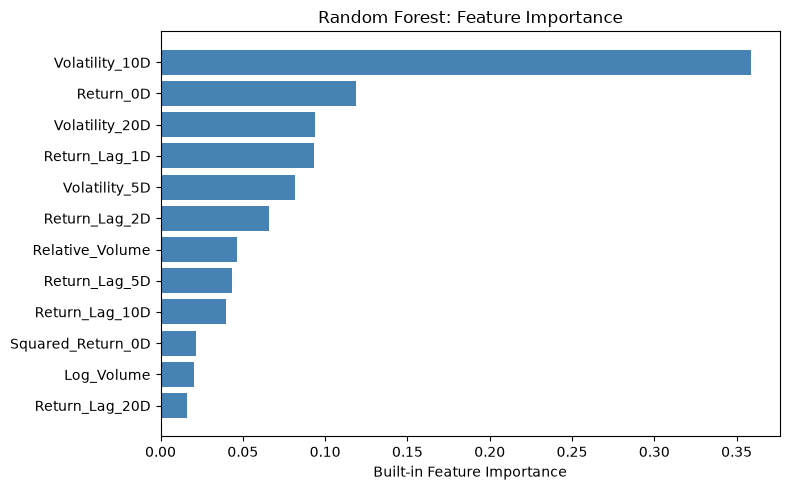

In [29]:
# Fit the selected configuration on all development observations
X_development = development_df[feature_cols].to_numpy(dtype=np.float32)

y_development = (development_df[TARGET].to_numpy()*best_target_scale)

best_model = clone(best_estimator)
best_model.fit(X_development, y_development)

del X_development, y_development

# Record which fitted model belongs to the selected configuration
final_model_metadata = {
    "name": best_name,
    "family": best_model_family,
    "target_scale": best_target_scale,
    "features": list(feature_cols),
    "development_cv_signature": development_cv_signature,
    "estimator_signature": estimator_signature(best_model),
    "model_object_id": id(best_model),
    "training_rows": len(development_df),
    "training_end": str(development_df[DATE_COL].max().date())
}
print("Fitted selected model:", best_name)
print("Training observations:", len(development_df))

if best_model_family == "Ridge":

    # Coefficients correspond to standardized input features
    coefficients = best_model.named_steps["ridge"].coef_

    interpretation = pd.DataFrame({
        "Feature": feature_cols,
        "Coefficient": coefficients})

    interpretation["Absolute_Coefficient"] = (interpretation["Coefficient"].abs())

    interpretation = interpretation.sort_values("Absolute_Coefficient", ascending=False)

    display(interpretation.round(6))

    plot_data = interpretation.sort_values("Absolute_Coefficient")

    colors = [
        "steelblue" if value >= 0 else "darkorange"
        for value in plot_data["Coefficient"]]

    plt.figure(figsize=(8, 5))
    plt.barh(
        plot_data["Feature"],
        plot_data["Coefficient"],
        color=colors)

    plt.axvline(0, color="gray", linewidth=1)
    plt.xlabel("Coefficient for a one-standard-deviation increase")
    plt.title(f"{best_model_family}: Standardized Feature Coefficients")

elif hasattr(best_model, "feature_importances_"):

    # Use built-in tree importance for a lightweight first analysis
    interpretation = pd.DataFrame({
        "Feature": feature_cols,
        "Importance": best_model.feature_importances_}).sort_values("Importance", ascending=False)

    display(interpretation.round(4))

    plot_data = interpretation.sort_values("Importance")

    plt.figure(figsize=(8, 5))
    plt.barh(plot_data["Feature"], plot_data["Importance"], color="steelblue")
    plt.xlabel("Built-in Feature Importance")
    plt.title(f"{best_model_family}: Feature Importance")

else:
    raise TypeError("The selected estimator has no supported interpretation.")

plt.tight_layout()
plt.show()


# ============================================================
# PART 6 - Final Test Evaluation
# ============================================================


## 6.1 - Test Data Validation

Check that the selected model is fitted and the test data are complete. Reuse the model from 5.8 and match the historical baseline to the same stock-date observations. Confirm that development target windows end before the test period.


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.utils.validation import check_is_fitted

# Verify inputs from the previous sections
evaluation_dependencies = [
    "best_model", "best_name", "best_model_family", "best_target_scale",
    "final_model_metadata", "best_estimator", "development_cv_signature", "development_df",
    "test_df", "test_baseline", "feature_cols", "TARGET", "DATE_COL",
    "TICKER_COL", "HZ", "evaluate_variance"
]
evaluation_missing = [
    name for name in evaluation_dependencies if name not in globals()
]
if evaluation_missing:
    raise RuntimeError(
        "Run the notebook through Section 5.8 first. Missing: "
        + ", ".join(evaluation_missing)
    )

check_is_fitted(best_model)
if (
    final_model_metadata["name"] != best_name
    or final_model_metadata["family"] != best_model_family
    or final_model_metadata["target_scale"] != best_target_scale
    or final_model_metadata["features"] != list(feature_cols)
    or final_model_metadata["development_cv_signature"] != development_cv_signature
    or final_model_metadata["model_object_id"] != id(best_model)
    or final_model_metadata["estimator_signature"] != estimator_signature(best_estimator)
    or final_model_metadata["estimator_signature"] != estimator_signature(best_model)
):
    raise ValueError("The fitted model is stale. Rerun Section 5.8 after model selection.")
evaluation_scale = float(best_target_scale)
if not np.isfinite(evaluation_scale) or evaluation_scale <= 0:
    raise ValueError("best_target_scale must be a positive finite number.")

evaluation_expected_scale = {
    "Ridge": 1.0, "Random Forest": 1.0, "XGBoost": 10000.0
}.get(best_model_family)
if (
    evaluation_expected_scale is not None
    and evaluation_scale != evaluation_expected_scale
):
    raise ValueError("The selected model and its target scaling do not match.")

evaluation_keys = [TICKER_COL, DATE_COL]
evaluation_features = list(feature_cols)
if (
    not evaluation_features
    or len(evaluation_features) != len(set(evaluation_features))
    or TARGET in evaluation_features
):
    raise ValueError("Predictors must be unique and must exclude the target.")

evaluation_required = (
    evaluation_keys + evaluation_features + [TARGET, "Trading_Day_Index"]
)
for evaluation_label, evaluation_frame, evaluation_columns in [
    ("test_df", test_df, evaluation_required),
    ("test_baseline", test_baseline, evaluation_keys + ["Baseline_Variance"]),
    ("development_df", development_df, [DATE_COL, TARGET, "Trading_Day_Index"])
]:
    evaluation_absent = set(evaluation_columns) - set(evaluation_frame.columns)
    if evaluation_absent:
        raise ValueError(
            f"{evaluation_label} is missing columns: {sorted(evaluation_absent)}"
        )
    if evaluation_frame.empty:
        raise ValueError(f"{evaluation_label} has no observations.")
    if not evaluation_frame.columns.is_unique:
        raise ValueError(f"{evaluation_label} has duplicate column names.")

if (
    test_df[evaluation_keys].isna().any().any()
    or test_baseline[evaluation_keys].isna().any().any()
):
    raise ValueError("Test and baseline stock-date keys must be complete.")

if (
    test_df.duplicated(evaluation_keys).any()
    or test_baseline.duplicated(evaluation_keys).any()
):
    raise ValueError("Test and baseline stock-date keys must be unique.")

if (
    development_df[DATE_COL].max() >= test_df[DATE_COL].min()
    or development_df["Trading_Day_Index"].max() + HZ
    >= test_df["Trading_Day_Index"].min()
):
    raise ValueError("Development target windows overlap the test period.")

# Match baseline forecasts to test observations by stock and date
evaluation_test = (
    test_df[evaluation_required]
    .copy()
    .sort_values([DATE_COL, TICKER_COL])
    .reset_index(drop=True)
)
evaluation_test = evaluation_test.merge(
    test_baseline[evaluation_keys + ["Baseline_Variance"]],
    on=evaluation_keys,
    how="left",
    validate="one_to_one"
)

evaluation_X = evaluation_test[evaluation_features].to_numpy(dtype=np.float32)
evaluation_actual_variance = evaluation_test[TARGET].to_numpy(dtype=float)
evaluation_baseline_variance = (
    evaluation_test["Baseline_Variance"].to_numpy(dtype=float)
)

if not np.isfinite(evaluation_X).all():
    raise ValueError("Test predictors contain missing or infinite values.")
for evaluation_label, evaluation_values in [
    ("Test targets", evaluation_actual_variance),
    ("Baseline forecasts", evaluation_baseline_variance)
]:
    if (
        not np.isfinite(evaluation_values).all()
        or (evaluation_values < 0).any()
    ):
        raise ValueError(f"{evaluation_label} must be finite and nonnegative.")

if (
    hasattr(best_model, "n_features_in_")
    and best_model.n_features_in_ != len(evaluation_features)
):
    raise ValueError("The test predictor count differs from the fitted model.")

# Define the high-volatility threshold using development data
evaluation_development_variance = (
    development_df[TARGET].to_numpy(dtype=float)
)
if (
    not np.isfinite(evaluation_development_variance).all()
    or (evaluation_development_variance < 0).any()
):
    raise ValueError("Development targets must be finite and nonnegative.")
evaluation_high_vol_threshold = float(
    np.quantile(np.sqrt(evaluation_development_variance) * 100, 0.90)
)

final_evaluation_setup = pd.DataFrame({
    "Item": [
        "Selected configuration", "Target scaling factor", "Test start",
        "Test end", "Test observations", "Test stocks", "Test trading dates",
        "Development 90th-percentile five-day volatility (%)"
    ],
    "Value": [
        str(best_name), evaluation_scale,
        str(pd.Timestamp(evaluation_test[DATE_COL].min()).date()),
        str(pd.Timestamp(evaluation_test[DATE_COL].max()).date()),
        len(evaluation_test), evaluation_test[TICKER_COL].nunique(),
        evaluation_test[DATE_COL].nunique(), evaluation_high_vol_threshold
    ]
})
display(final_evaluation_setup)


,Item,Value
0,Selected configuration,RandomForest_trees_100_depth_10_leaf_20
1,Target scaling factor,1.0
2,Test start,2025-10-10
3,Test end,2026-10-13
4,Test observations,126580
5,Test stocks,502
6,Test trading dates,253
7,Development 90th-percentile five-day volatilit...,7.546784


## 6.2 - Test Set Performance

Compare the selected model and historical baseline using MAE and RMSE on the five-day volatility scale. Report improvement relative to the baseline, mean forecast error, and the proportion of underestimated forecasts.

Errors are measured in volatility percentage points. Negative errors indicate underestimation; negative improvement indicates worse performance than the baseline.


In [31]:
# Predict test variance and restore the original target units
evaluation_X = evaluation_test[evaluation_features].to_numpy(dtype=np.float32)
evaluation_raw_predictions = np.asarray(
    best_model.predict(evaluation_X), dtype=float
).reshape(-1)
if (
    len(evaluation_raw_predictions) != len(evaluation_test)
    or not np.isfinite(evaluation_raw_predictions).all()
):
    raise ValueError("Model predictions must be finite and match the test rows.")

evaluation_unclipped_variance = (
    evaluation_raw_predictions / evaluation_scale
)
evaluation_model_variance = np.maximum(evaluation_unclipped_variance, 0.0)

final_test_predictions = evaluation_test[
    evaluation_keys + [TARGET, "Baseline_Variance"]
].copy()
final_test_predictions["Model_Variance"] = evaluation_model_variance
final_test_predictions["Actual_Volatility_Pct"] = (
    np.sqrt(evaluation_actual_variance) * 100
)
final_test_predictions["Baseline_Volatility_Pct"] = (
    np.sqrt(evaluation_baseline_variance) * 100
)
final_test_predictions["Model_Volatility_Pct"] = (
    np.sqrt(evaluation_model_variance) * 100
)

evaluation_metric_rows = []
for evaluation_method, evaluation_variance, evaluation_prefix in [
    ("Historical baseline", evaluation_baseline_variance, "Baseline"),
    ("Selected model", evaluation_model_variance, "Model")
]:
    evaluation_error = (
        final_test_predictions[f"{evaluation_prefix}_Volatility_Pct"]
        - final_test_predictions["Actual_Volatility_Pct"]
    )
    final_test_predictions[f"{evaluation_prefix}_Error_Pp"] = evaluation_error
    final_test_predictions[f"{evaluation_prefix}_Abs_Error_Pp"] = (
        evaluation_error.abs()
    )
    final_test_predictions[f"{evaluation_prefix}_Squared_Error"] = (
        evaluation_error ** 2
    )
    evaluation_metrics = evaluate_variance(
        evaluation_actual_variance, evaluation_variance
    )
    evaluation_metric_rows.append({
        "Method": evaluation_method,
        "Observations": len(evaluation_test),
        "MAE (pp)": evaluation_metrics["MAE (%)"],
        "RMSE (pp)": evaluation_metrics["RMSE (%)"],
        "Mean error (pp)": evaluation_error.mean(),
        "Underestimation rate (%)": evaluation_error.lt(0).mean() * 100,
        "Zero forecasts": int((evaluation_variance == 0).sum())
    })

final_test_summary = pd.DataFrame(evaluation_metric_rows).set_index("Method")
for evaluation_metric in ["MAE", "RMSE"]:
    evaluation_baseline_score = final_test_summary.loc[
        "Historical baseline", f"{evaluation_metric} (pp)"
    ]
    final_test_summary[f"{evaluation_metric} improvement vs baseline (%)"] = (
        (evaluation_baseline_score - final_test_summary[f"{evaluation_metric} (pp)"])
        / evaluation_baseline_score * 100
        if evaluation_baseline_score > 0 else np.nan
    )

display(final_test_summary.round(4))
print(
    "Negative raw variance forecasts clipped to zero: "
    f"{int((evaluation_unclipped_variance < 0).sum()):,}"
)
print("Positive improvement means a lower error than the baseline.")
del evaluation_X


,Observations,MAE (pp),RMSE (pp),Mean error (pp),Underestimation rate (%),Zero forecasts,MAE improvement vs baseline (%),RMSE improvement vs baseline (%)
Method,,,,,,,,
Historical baseline,126580,2.1214,3.3500,0.0032,49.3593,0,0.0000,0.0000
Selected model,126580,1.8801,2.7572,0.5871,30.4740,0,11.3756,17.6959


Negative raw variance forecasts clipped to zero: 0
Positive improvement means a lower error than the baseline.


## 6.3 - Risk Evaluation

Apply a fixed risk budget to each stock-date observation. Use forecast volatility to set exposure, then compare the resulting realized risk with the budget. Compare the selected model, historical baseline, and an unscaled position.

| Assumption | Setting |
|---|---|
| Five-day volatility budget | 2% |
| Exposure range | 0% to 100%; no leverage |
| Minimum forecast volatility | 0.5% over five days |
| Primary evaluation | Non-overlapping five-day windows, starting at the first test date |
| Supporting comparison | All daily forecast windows |

For the two forecast-based methods:

$$
w_{i,t}=\min\left(1,\frac{0.02}{\max(\widehat{\sigma}_{i,t}^{5D},0.005)}\right)
$$

The realized risk proxy is the exposure multiplied by realized five-day volatility:

$$
\text{Realized risk}_{i,t}=w_{i,t}\sqrt{\text{Future Variance}_{i,t}^{5D}}
$$

Each row is a separate single-stock allocation with constant exposure over the window; the remaining allocation is cash. The exposures are not combined into a portfolio. The unscaled comparison keeps exposure at 100%.

The sizing rule uses the volatility-targeting idea described by [Harvey et al. (2018), The Impact of Volatility Targeting](https://people.duke.edu/~charvey/Research/Published_Papers/P135_The_impact_of.pdf). The budget and limits here are fixed illustrative assumptions, not parameters selected to maximize test performance.


In [32]:
# Set the same risk-budget assumptions for all methods
RISK_BUDGET_5D = 0.02
RISK_MAX_EXPOSURE = 1.0
RISK_FORECAST_FLOOR = 0.005
RISK_SEVERE_RATIO = 1.5
RISK_TRACKING_BAND = 0.20
RISK_METHODS = ["Unscaled", "Historical baseline", "Selected model"]

risk_dependencies = [
    "final_test_predictions", "test_df", "development_df",
    "TARGET", "DATE_COL", "TICKER_COL", "HZ"
]
risk_missing = [name for name in risk_dependencies if name not in globals()]
if risk_missing:
    raise RuntimeError(
        "Run Sections 6.1 and 6.2 first. Missing: " + ", ".join(risk_missing)
    )
if HZ != 5:
    raise ValueError("This risk budget is defined for a five-trading-day horizon.")
if not (
    0 < RISK_BUDGET_5D
    and 0 < RISK_FORECAST_FLOOR
    and 0 < RISK_MAX_EXPOSURE <= 1
):
    raise ValueError("Risk budget, volatility floor, and exposure cap are invalid.")

risk_keys = [TICKER_COL, DATE_COL]
risk_variance_columns = [TARGET, "Baseline_Variance", "Model_Variance"]
risk_required_columns = risk_keys + risk_variance_columns
risk_absent = set(risk_required_columns) - set(final_test_predictions.columns)
if risk_absent:
    raise ValueError(f"Missing risk-evaluation columns: {sorted(risk_absent)}")

risk_inputs = final_test_predictions[risk_required_columns].copy()
if (
    risk_inputs.empty
    or risk_inputs[risk_keys].isna().any().any()
    or risk_inputs.duplicated(risk_keys).any()
):
    raise ValueError("Risk evaluation requires complete, unique stock-date keys.")
risk_variance_values = risk_inputs[risk_variance_columns].to_numpy(dtype=float)
if (
    not np.isfinite(risk_variance_values).all()
    or (risk_variance_values < 0).any()
):
    raise ValueError("Actual and forecast variances must be finite and nonnegative.")

# Reuse trading-calendar positions to select non-overlapping decision dates
risk_calendar_columns = [DATE_COL, "Trading_Day_Index"]
if not set(risk_calendar_columns).issubset(test_df.columns):
    raise ValueError("test_df must contain dates and trading-calendar positions.")
risk_calendar = test_df[risk_calendar_columns].drop_duplicates().copy()
if (
    risk_calendar.empty
    or risk_calendar.isna().any().any()
    or risk_calendar[DATE_COL].duplicated().any()
):
    raise ValueError("Each test date must map to one trading-calendar position.")
risk_calendar = risk_calendar.sort_values(DATE_COL).reset_index(drop=True)
risk_positions = risk_calendar["Trading_Day_Index"].to_numpy(dtype=float)
if (
    not np.isfinite(risk_positions).all()
    or not np.equal(risk_positions, np.floor(risk_positions)).all()
    or (np.diff(risk_positions) <= 0).any()
):
    raise ValueError("Trading-calendar positions must be increasing integers.")
risk_expected_keys = test_df[risk_keys].drop_duplicates()
risk_key_check = risk_expected_keys.merge(
    risk_inputs[risk_keys], on=risk_keys, how="outer", indicator=True
)
if not risk_key_check["_merge"].eq("both").all():
    raise ValueError("Risk forecasts must match all stock-date keys in test_df.")
risk_inputs = risk_inputs.merge(
    risk_calendar, on=DATE_COL, how="left", validate="many_to_one"
)
if risk_inputs["Trading_Day_Index"].isna().any():
    raise ValueError("Some forecast dates have no trading-calendar position.")

risk_nonoverlap_dates = []
risk_last_position = None
for risk_date, risk_position in risk_calendar.itertuples(index=False, name=None):
    if risk_last_position is None or risk_position >= risk_last_position + HZ:
        risk_nonoverlap_dates.append(risk_date)
        risk_last_position = risk_position
risk_inputs["Non_Overlapping"] = risk_inputs[DATE_COL].isin(risk_nonoverlap_dates)

# Define high-volatility outcomes using the development-period threshold
risk_development_variance = development_df[TARGET].to_numpy(dtype=float)
if (
    len(risk_development_variance) == 0
    or not np.isfinite(risk_development_variance).all()
    or (risk_development_variance < 0).any()
):
    raise ValueError("Development targets must be finite and nonnegative.")
risk_high_volatility_threshold = float(
    np.quantile(np.sqrt(risk_development_variance), 0.90)
)
risk_inputs["Actual_Volatility"] = np.sqrt(
    risk_inputs[TARGET].to_numpy(dtype=float)
)
risk_inputs["Volatility_Group"] = np.where(
    risk_inputs["Actual_Volatility"] > risk_high_volatility_threshold,
    "High realized volatility", "Other observations"
)

# Size positions using forecasts only; actual outcomes are used to score them
risk_application_frames = []
for risk_method, risk_forecast_column in [
    ("Unscaled", None),
    ("Historical baseline", "Baseline_Variance"),
    ("Selected model", "Model_Variance")
]:
    risk_frame = risk_inputs[
        risk_keys + [
            "Trading_Day_Index", "Non_Overlapping",
            "Actual_Volatility", "Volatility_Group"
        ]
    ].copy()
    risk_frame["Method"] = risk_method
    if risk_forecast_column is None:
        risk_exposure = np.ones(len(risk_frame), dtype=float)
    else:
        risk_forecast_volatility = np.sqrt(
            risk_inputs[risk_forecast_column].to_numpy(dtype=float)
        )
        risk_exposure = np.minimum(
            RISK_MAX_EXPOSURE,
            RISK_BUDGET_5D / np.maximum(
                risk_forecast_volatility, RISK_FORECAST_FLOOR
            )
        )
    risk_frame["Exposure"] = risk_exposure
    risk_frame["Realized_Risk"] = (
        risk_exposure * risk_frame["Actual_Volatility"].to_numpy(dtype=float)
    )
    risk_frame["Risk_Budget_Ratio"] = (
        risk_frame["Realized_Risk"] / RISK_BUDGET_5D
    )
    risk_frame["Budget_Error_Pp"] = (
        risk_frame["Realized_Risk"] - RISK_BUDGET_5D
    ) * 100
    risk_frame["Over_Budget"] = risk_frame["Risk_Budget_Ratio"] > 1 + 1e-12
    risk_frame["Severe_Overrun"] = (
        risk_frame["Risk_Budget_Ratio"] > RISK_SEVERE_RATIO + 1e-12
    )
    risk_frame["Within_Band"] = (
        (risk_frame["Risk_Budget_Ratio"] >= 1 - RISK_TRACKING_BAND - 1e-12)
        & (risk_frame["Risk_Budget_Ratio"] <= 1 + RISK_TRACKING_BAND + 1e-12)
    )
    risk_application_frames.append(risk_frame)

risk_application_predictions = pd.concat(
    risk_application_frames, ignore_index=True
)
risk_primary_predictions = risk_application_predictions.loc[
    risk_application_predictions["Non_Overlapping"]
].copy()

risk_application_setup = pd.DataFrame({
    "Item": [
        "Five-day risk budget (%)", "Maximum exposure (%)",
        "Forecast-volatility floor (%)", "Non-overlapping decision dates",
        "Stock-date decisions per method", "High-volatility threshold (%)"
    ],
    "Value": [
        RISK_BUDGET_5D * 100, RISK_MAX_EXPOSURE * 100,
        RISK_FORECAST_FLOOR * 100, len(risk_nonoverlap_dates),
        int(risk_inputs["Non_Overlapping"].sum()),
        risk_high_volatility_threshold * 100
    ]
})
display(risk_application_setup)


,Item,Value
0,Five-day risk budget (%),2.000000
1,Maximum exposure (%),100.000000
2,Forecast-volatility floor (%),0.500000
3,Non-overlapping decision dates,51.000000
4,Stock-date decisions per method,25516.000000
5,High-volatility threshold (%),7.546784


### 6.3.1 - Risk-Budget Performance

Measure how closely realized risk tracks the 2% budget. Budget MAE and RMSE measure deviations on both sides; exceedance rates focus on risk above the budget. The severe-overrun threshold is 1.5 times the budget, or 3% five-day volatility.

Read these results alongside average exposure. A lower exceedance rate can result from holding less stock, so it does not establish better risk allocation by itself. Results within 20% of budget fall between 1.6% and 2.4%; this is a tracking band, not a confidence interval.


In [33]:
# Compare risk-budget tracking and exposure on the same decisions
def summarize_risk_application(risk_data):
    risk_rows = []
    for risk_method in RISK_METHODS:
        risk_group = risk_data.loc[risk_data["Method"] == risk_method]
        if risk_group.empty:
            continue
        risk_error = risk_group["Budget_Error_Pp"].to_numpy(dtype=float)
        risk_rows.append({
            "Method": risk_method,
            "Decisions": len(risk_group),
            "Average exposure (%)": risk_group["Exposure"].mean() * 100,
            "Mean realized risk (%)": risk_group["Realized_Risk"].mean() * 100,
            "Budget MAE (pp)": np.abs(risk_error).mean(),
            "Budget RMSE (pp)": np.sqrt(np.mean(risk_error ** 2)),
            "Over-budget rate (%)": risk_group["Over_Budget"].mean() * 100,
            "Over 1.5x budget (%)": risk_group["Severe_Overrun"].mean() * 100,
            "95th percentile risk/budget": risk_group[
                "Risk_Budget_Ratio"
            ].quantile(0.95),
            "Within 20% of budget (%)": risk_group["Within_Band"].mean() * 100
        })
    return pd.DataFrame(risk_rows).set_index("Method").reindex(RISK_METHODS)

risk_application_summary = summarize_risk_application(risk_primary_predictions)
risk_application_daily_summary = summarize_risk_application(
    risk_application_predictions
)

print("Primary comparison: non-overlapping five-day windows")
display(risk_application_summary.T.round(4))

risk_regime_tables = []
for risk_regime, risk_group in risk_primary_predictions.groupby(
    "Volatility_Group", sort=False
):
    risk_regime_table = summarize_risk_application(risk_group).reset_index()
    risk_regime_table.insert(0, "Volatility group", risk_regime)
    risk_regime_tables.append(risk_regime_table)
risk_application_regime_summary = pd.concat(
    risk_regime_tables, ignore_index=True
)

print("Risk-budget performance by realized volatility")
display(risk_application_regime_summary[[
    "Volatility group", "Method", "Decisions", "Average exposure (%)",
    "Budget RMSE (pp)", "Over-budget rate (%)", "Over 1.5x budget (%)"
]].round(4))

print("Supporting comparison: all daily forecast windows")
display(risk_application_daily_summary[[
    "Decisions", "Average exposure (%)", "Budget RMSE (pp)",
    "Over-budget rate (%)", "Over 1.5x budget (%)"
]].T.round(4))


Primary comparison: non-overlapping five-day windows


Method,Unscaled,Historical baseline,Selected model
Decisions,25516.0000,25516.0000,25516.0000
Average exposure (%),100.0000,58.3974,44.4268
Mean realized risk (%),4.4082,2.2871,1.7712
Budget MAE (pp),2.5380,1.0057,0.7500
Budget RMSE (pp),3.9046,1.5755,1.0273
Over-budget rate (%),86.5614,47.4683,30.4123
Over 1.5x budget (%),63.9559,21.4689,8.3124
95th percentile risk/budget,4.9734,2.4673,1.7142
Within 20% of budget (%),15.2218,28.0726,30.5612


Risk-budget performance by realized volatility


,Volatility group,Method,Decisions,Average exposure (%),Budget RMSE (pp),Over-budget rate (%),Over 1.5x budget (%)
0,Other observations,Unscaled,22787,100.0000,2.2414,84.9519,59.6393
1,Other observations,Historical baseline,22787,60.7845,1.1158,43.5994,17.3915
2,Other observations,Selected model,22787,46.0164,0.7861,23.8338,3.2299
3,High realized volatility,Unscaled,2729,100.0000,10.0299,100.0000,100.0000
4,High realized volatility,Historical baseline,2729,38.4652,3.5795,79.7728,55.5148
5,High realized volatility,Selected model,2729,31.1537,2.1699,85.3426,50.7512


Supporting comparison: all daily forecast windows


Method,Unscaled,Historical baseline,Selected model
Decisions,126580.0000,126580.0000,126580.0000
Average exposure (%),100.0000,58.4219,44.5526
Budget RMSE (pp),3.9049,1.5754,1.0250
Over-budget rate (%),86.5168,47.6402,30.4740
Over 1.5x budget (%),63.9469,21.4236,8.2746


### 6.3.2 - Risk Application Plots

Compare exposure, risk-budget exceedances, and the distribution of realized risk relative to budget. The time series shows the cross-sectional median of separate stock decisions. Box plots omit outlier markers for readability; all observations remain in the tables and tail-risk statistics.


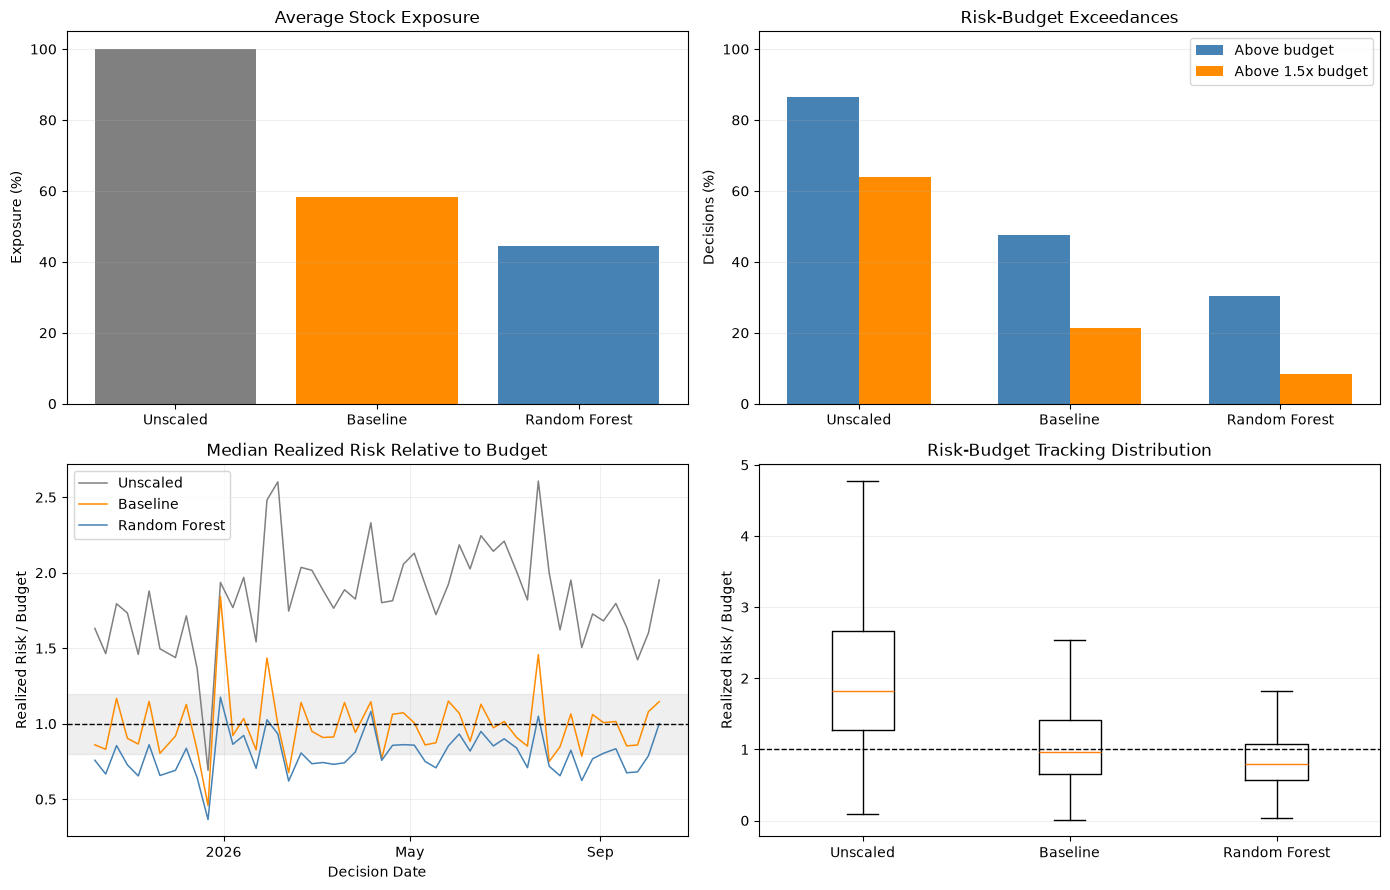

In [34]:
import matplotlib.dates as mdates

risk_colors = ["gray", "darkorange", "steelblue"]
risk_labels = ["Unscaled", "Baseline", best_model_family]
risk_plot_x = np.arange(len(RISK_METHODS))
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].bar(
    risk_plot_x, risk_application_summary["Average exposure (%)"],
    color=risk_colors
)
axes[0, 0].set_xticks(risk_plot_x, risk_labels)
axes[0, 0].set(
    title="Average Stock Exposure", ylabel="Exposure (%)", ylim=(0, 105)
)
axes[0, 0].grid(axis="y", alpha=0.2)

risk_bar_width = 0.34
axes[0, 1].bar(
    risk_plot_x - risk_bar_width / 2,
    risk_application_summary["Over-budget rate (%)"],
    risk_bar_width, label="Above budget", color="steelblue"
)
axes[0, 1].bar(
    risk_plot_x + risk_bar_width / 2,
    risk_application_summary["Over 1.5x budget (%)"],
    risk_bar_width, label="Above 1.5x budget", color="darkorange"
)
axes[0, 1].set_xticks(risk_plot_x, risk_labels)
axes[0, 1].set(
    title="Risk-Budget Exceedances", ylabel="Decisions (%)", ylim=(0, 105)
)
axes[0, 1].legend()
axes[0, 1].grid(axis="y", alpha=0.2)

risk_daily_ratios = (
    risk_primary_predictions.groupby([DATE_COL, "Method"])[
        "Risk_Budget_Ratio"
    ].median().unstack("Method").reindex(columns=RISK_METHODS)
)
for risk_method, risk_label, risk_color in zip(
    RISK_METHODS, risk_labels, risk_colors
):
    axes[1, 0].plot(
        risk_daily_ratios.index, risk_daily_ratios[risk_method],
        label=risk_label, color=risk_color, linewidth=1.1
    )
axes[1, 0].axhline(1, color="black", linestyle="--", linewidth=1)
axes[1, 0].axhspan(
    1 - RISK_TRACKING_BAND, 1 + RISK_TRACKING_BAND,
    color="gray", alpha=0.12
)
axes[1, 0].set(
    title="Median Realized Risk Relative to Budget",
    xlabel="Decision Date", ylabel="Realized Risk / Budget"
)
risk_date_locator = mdates.AutoDateLocator(minticks=3, maxticks=5)
axes[1, 0].xaxis.set_major_locator(risk_date_locator)
axes[1, 0].xaxis.set_major_formatter(
    mdates.ConciseDateFormatter(risk_date_locator)
)
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.2)

risk_box_values = [
    risk_primary_predictions.loc[
        risk_primary_predictions["Method"] == risk_method,
        "Risk_Budget_Ratio"
    ].to_numpy(dtype=float)
    for risk_method in RISK_METHODS
]
axes[1, 1].boxplot(risk_box_values, showfliers=False)
axes[1, 1].set_xticks(np.arange(1, 4), risk_labels)
axes[1, 1].axhline(1, color="black", linestyle="--", linewidth=1)
axes[1, 1].set(
    title="Risk-Budget Tracking Distribution",
    ylabel="Realized Risk / Budget"
)
axes[1, 1].grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


### 6.3.3 - Risk Application Summary

Summarize budget tracking, exceedances, and exposure for the selected model and baseline. Check whether the comparison changes during high-volatility periods or when all daily windows are included.


In [35]:
risk_model_result = risk_application_summary.loc["Selected model"]
risk_baseline_result = risk_application_summary.loc["Historical baseline"]

print(
    f"Risk budget: {RISK_BUDGET_5D * 100:.2f}% over {HZ} trading days | "
    f"Exposure cap: {RISK_MAX_EXPOSURE * 100:.0f}%"
)
print(
    f"Primary sample: {int(risk_model_result['Decisions']):,} stock-date "
    f"decisions per method across {len(risk_nonoverlap_dates)} decision dates."
)
print(
    f"Budget RMSE - Model: {risk_model_result['Budget RMSE (pp)']:.4f} pp | "
    f"Baseline: {risk_baseline_result['Budget RMSE (pp)']:.4f} pp"
)
if risk_baseline_result["Budget RMSE (pp)"] > 1e-12:
    risk_rmse_improvement = (
        (risk_baseline_result["Budget RMSE (pp)"]
         - risk_model_result["Budget RMSE (pp)"])
        / risk_baseline_result["Budget RMSE (pp)"] * 100
    )
    print(
        f"Budget RMSE improvement vs baseline: {risk_rmse_improvement:.2f}% "
        "(positive means closer tracking)."
    )
else:
    print("Relative budget RMSE improvement is undefined: baseline error is zero.")

risk_exceedance_difference = (
    risk_model_result["Over-budget rate (%)"]
    - risk_baseline_result["Over-budget rate (%)"]
)
print(
    f"Over-budget rate - Model: {risk_model_result['Over-budget rate (%)']:.2f}% | "
    f"Baseline: {risk_baseline_result['Over-budget rate (%)']:.2f}% | "
    f"Model minus baseline: {risk_exceedance_difference:+.2f} pp"
)
print(
    f"Average exposure - Model: {risk_model_result['Average exposure (%)']:.2f}% | "
    f"Baseline: {risk_baseline_result['Average exposure (%)']:.2f}%"
)
risk_rmse_gap = (
    risk_model_result["Budget RMSE (pp)"]
    - risk_baseline_result["Budget RMSE (pp)"]
)
if risk_rmse_gap < 0 and risk_exceedance_difference < 0:
    print(
        "The selected model tracked the budget more closely and exceeded "
        "it less often under this sizing rule. Read this result with exposure "
        "levels; it does not establish a return advantage."
    )
elif risk_rmse_gap > 0 and risk_exceedance_difference > 0:
    print(
        "The historical baseline tracked the budget more closely and "
        "exceeded it less often under this sizing rule."
    )
else:
    print(
        "Budget tracking and exceedance frequency give mixed or equal "
        "results. Lower exposure can reduce exceedances while leaving "
        "more of the risk budget unused."
    )

risk_high_results = risk_application_regime_summary.loc[
    risk_application_regime_summary["Volatility group"]
    == "High realized volatility"
].set_index("Method")
if not risk_high_results.empty:
    print(
        "High-volatility over-budget rate - "
        f"Model: {risk_high_results.loc['Selected model', 'Over-budget rate (%)']:.2f}% | "
        f"Baseline: {risk_high_results.loc['Historical baseline', 'Over-budget rate (%)']:.2f}%"
    )
else:
    print("No primary-sample decisions fall in the high-volatility group.")

risk_daily_rmse_gap = (
    risk_application_daily_summary.loc["Selected model", "Budget RMSE (pp)"]
    - risk_application_daily_summary.loc["Historical baseline", "Budget RMSE (pp)"]
)
if risk_rmse_gap * risk_daily_rmse_gap < 0:
    print(
        "The budget-RMSE ranking reverses when all overlapping daily windows "
        "are included. The result depends on the evaluation schedule."
    )
else:
    print("The budget-RMSE ranking does not reverse with all daily windows.")

print(
    "This is an exploratory single-stock risk-allocation experiment. "
    "No model, risk budget, or exposure rule is selected using these results."
)


Risk budget: 2.00% over 5 trading days | Exposure cap: 100%
Primary sample: 25,516 stock-date decisions per method across 51 decision dates.
Budget RMSE - Model: 1.0273 pp | Baseline: 1.5755 pp
Budget RMSE improvement vs baseline: 34.79% (positive means closer tracking).
Over-budget rate - Model: 30.41% | Baseline: 47.47% | Model minus baseline: -17.06 pp
Average exposure - Model: 44.43% | Baseline: 58.40%
The selected model tracked the budget more closely and exceeded it less often under this sizing rule. Read this result with exposure levels; it does not establish a return advantage.
High-volatility over-budget rate - Model: 85.34% | Baseline: 79.77%
The budget-RMSE ranking does not reverse with all daily windows.
This is an exploratory single-stock risk-allocation experiment. No model, risk budget, or exposure rule is selected using these results.


### 6.3.4 - Risk Application Limitations

- Realized risk is a constant-exposure volatility proxy, not the return or volatility of an executed portfolio. Stock positions are evaluated separately.
- The 2% budget, volatility floor, and exposure cap are illustrative. The cap can leave the budget unused when forecast volatility is low; exposure is therefore reported alongside risk.
- Fees, financing, cash interest, and trading implementation are not modelled. This experiment does not establish profitability or Value-at-Risk coverage.
- Non-overlapping windows reduce repeated use of the same future returns. Stocks can still move together, so these results do not establish statistical significance.
- The risk application is added after the initial test results were reviewed. It is an exploratory business-use check, not a new independent test or a basis for retuning.

Detailed decisions are available in risk_application_predictions. The primary, daily-window, and volatility-group comparisons are stored in risk_application_summary, risk_application_daily_summary, and risk_application_regime_summary.


## 6.4 - Forecasts and Errors

Compare predicted and realized volatility using scatter plots, daily median stock volatility, and forecast-error distributions. Scatter plots use up to 5,000 observations for readability; metrics and error distributions use the full test set. Points below the diagonal indicate underestimation.


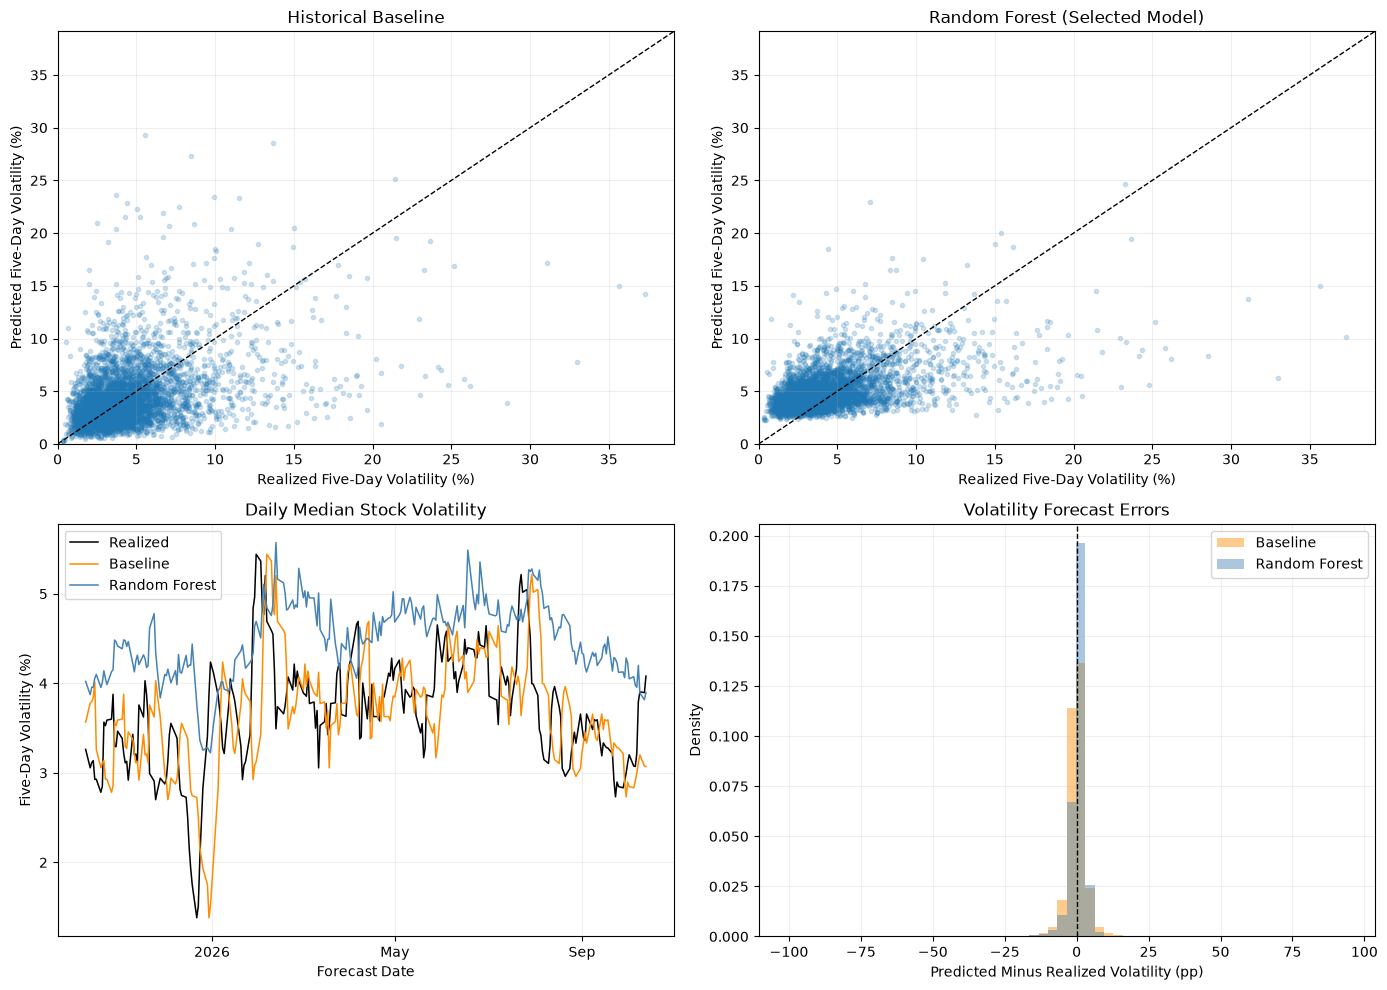

In [36]:
import matplotlib.dates as mdates

evaluation_plot_sample = final_test_predictions.sample(
    n=min(5000, len(final_test_predictions)),
    random_state=int(globals().get("RS", 69))
)
final_daily_volatility = (
    final_test_predictions.groupby(DATE_COL)[[
        "Actual_Volatility_Pct",
        "Baseline_Volatility_Pct",
        "Model_Volatility_Pct"
    ]].median()
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
evaluation_plot_limit = float(
    evaluation_plot_sample[[
        "Actual_Volatility_Pct",
        "Baseline_Volatility_Pct",
        "Model_Volatility_Pct"
    ]].to_numpy().max()
)
evaluation_plot_limit = (
    evaluation_plot_limit * 1.05 if evaluation_plot_limit > 0 else 1.0
)
for evaluation_ax, evaluation_prefix, evaluation_title in [
    (axes[0, 0], "Baseline", "Historical Baseline"),
    (axes[0, 1], "Model", f"{best_model_family} (Selected Model)")
]:
    evaluation_ax.scatter(
        evaluation_plot_sample["Actual_Volatility_Pct"],
        evaluation_plot_sample[f"{evaluation_prefix}_Volatility_Pct"],
        s=9, alpha=0.20
    )
    evaluation_ax.plot(
        [0, evaluation_plot_limit], [0, evaluation_plot_limit],
        color="black", linestyle="--", linewidth=1
    )
    evaluation_ax.set(
        xlim=(0, evaluation_plot_limit), ylim=(0, evaluation_plot_limit),
        xlabel="Realized Five-Day Volatility (%)",
        ylabel="Predicted Five-Day Volatility (%)",
        title=evaluation_title
    )
    evaluation_ax.grid(alpha=0.2)

for evaluation_column, evaluation_label, evaluation_color in [
    ("Actual_Volatility_Pct", "Realized", "black"),
    ("Baseline_Volatility_Pct", "Baseline", "darkorange"),
    ("Model_Volatility_Pct", best_model_family, "steelblue")
]:
    axes[1, 0].plot(
        final_daily_volatility.index, final_daily_volatility[evaluation_column],
        label=evaluation_label, color=evaluation_color, linewidth=1.1
    )
axes[1, 0].set(
    title="Daily Median Stock Volatility",
    xlabel="Forecast Date", ylabel="Five-Day Volatility (%)"
)
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.2)
evaluation_date_locator = mdates.AutoDateLocator(minticks=3, maxticks=5)
axes[1, 0].xaxis.set_major_locator(evaluation_date_locator)
axes[1, 0].xaxis.set_major_formatter(
    mdates.ConciseDateFormatter(evaluation_date_locator)
)

evaluation_all_errors = final_test_predictions[[
    "Baseline_Error_Pp", "Model_Error_Pp"
]].to_numpy().ravel()
evaluation_bins = np.histogram_bin_edges(evaluation_all_errors, bins=60)
for evaluation_prefix, evaluation_label, evaluation_color in [
    ("Baseline", "Baseline", "darkorange"),
    ("Model", best_model_family, "steelblue")
]:
    axes[1, 1].hist(
        final_test_predictions[f"{evaluation_prefix}_Error_Pp"],
        bins=evaluation_bins, density=True, alpha=0.45,
        label=evaluation_label, color=evaluation_color
    )
axes[1, 1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1, 1].set(
    title="Volatility Forecast Errors",
    xlabel="Predicted Minus Realized Volatility (pp)", ylabel="Density"
)
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 6.5 - Error Analysis

Examine errors across stocks and volatility conditions. Define high realized volatility using the 90th percentile of development-period five-day volatility. This groups test outcomes for error analysis; it is not a forecasting input. Include observation counts when comparing stocks with different historical coverage.


In [37]:
final_test_predictions["Volatility_Group"] = np.where(
    final_test_predictions["Actual_Volatility_Pct"]
        > evaluation_high_vol_threshold,
    "High realized volatility", "Other observations"
)

evaluation_regime_rows = []
for evaluation_group, evaluation_group_data in (
    final_test_predictions.groupby("Volatility_Group", sort=False)
):
    for evaluation_prefix, evaluation_method in [
        ("Baseline", "Historical baseline"), ("Model", "Selected model")
    ]:
        evaluation_regime_rows.append({
            "Group": evaluation_group,
            "Method": evaluation_method,
            "Observations": len(evaluation_group_data),
            "MAE (pp)": evaluation_group_data[
                f"{evaluation_prefix}_Abs_Error_Pp"
            ].mean(),
            "RMSE (pp)": np.sqrt(evaluation_group_data[
                f"{evaluation_prefix}_Squared_Error"
            ].mean()),
            "Mean error (pp)": evaluation_group_data[
                f"{evaluation_prefix}_Error_Pp"
            ].mean(),
            "Underestimation rate (%)": evaluation_group_data[
                f"{evaluation_prefix}_Error_Pp"
            ].lt(0).mean() * 100
        })
final_volatility_summary = pd.DataFrame(evaluation_regime_rows)

final_stock_summary = final_test_predictions.groupby(TICKER_COL).agg(
    Observations=(TARGET, "size"),
    Actual_Volatility_Mean_Pct=("Actual_Volatility_Pct", "mean"),
    Baseline_MAE_Pp=("Baseline_Abs_Error_Pp", "mean"),
    Model_MAE_Pp=("Model_Abs_Error_Pp", "mean"),
    Baseline_MSE=("Baseline_Squared_Error", "mean"),
    Model_MSE=("Model_Squared_Error", "mean"),
    Model_Mean_Error_Pp=("Model_Error_Pp", "mean")
)
final_stock_summary["Baseline_RMSE_Pp"] = np.sqrt(
    final_stock_summary.pop("Baseline_MSE")
)
final_stock_summary["Model_RMSE_Pp"] = np.sqrt(
    final_stock_summary.pop("Model_MSE")
)
evaluation_stock_baseline_rmse = (
    final_stock_summary["Baseline_RMSE_Pp"].to_numpy(dtype=float)
)
evaluation_stock_improvement = np.full(
    len(final_stock_summary), np.nan, dtype=float
)
np.divide(
    (evaluation_stock_baseline_rmse
     - final_stock_summary["Model_RMSE_Pp"].to_numpy(dtype=float)) * 100,
    evaluation_stock_baseline_rmse,
    out=evaluation_stock_improvement,
    where=evaluation_stock_baseline_rmse > 0
)
final_stock_summary["RMSE_Improvement_vs_Baseline_Pct"] = (
    evaluation_stock_improvement
)
final_stock_summary = final_stock_summary.sort_values(
    "Model_RMSE_Pp", ascending=False
)

display(final_volatility_summary.round(4))
print(
    "High-volatility threshold from development data: "
    f"{evaluation_high_vol_threshold:.4f}%"
)
print("Ten stocks with the largest selected-model test RMSE:")
display(final_stock_summary.head(10).round(4))


,Group,Method,Observations,MAE (pp),RMSE (pp),Mean error (pp),Underestimation rate (%)
0,Other observations,Historical baseline,113102,1.7443,2.5487,0.4449,45.6765
1,Other observations,Selected model,113102,1.5804,2.0273,1.1032,23.8537
2,High realized volatility,Historical baseline,13478,5.2861,7.1334,-3.7031,80.2641
3,High realized volatility,Selected model,13478,4.3950,6.0752,-3.7439,86.0291


High-volatility threshold from development data: 7.5468%
Ten stocks with the largest selected-model test RMSE:


,Observations,Actual_Volatility_Mean_Pct,Baseline_MAE_Pp,Model_MAE_Pp,Model_Mean_Error_Pp,Baseline_RMSE_Pp,Model_RMSE_Pp,RMSE_Improvement_vs_Baseline_Pct
Ticker,,,,,,,,
MRNA,253,11.6315,7.8192,5.8172,-2.0248,19.0811,14.5284,23.8597
FISV,226,6.1863,4.6523,3.5112,-0.2162,11.7452,8.9331,23.9426
SMCI,253,11.2595,6.7157,5.0690,-0.7454,9.7661,7.6531,21.6360
HONA,63,7.4794,4.9865,3.9295,0.0709,8.9300,6.7336,24.5959
SNDK,253,14.7393,5.9043,4.9194,-2.3995,7.5804,6.3938,15.6533
BE,253,14.5935,6.4327,5.0544,-2.1699,8.1373,6.3075,22.4860
FICO,253,7.3941,5.1459,3.8309,-0.2771,7.6777,5.9996,21.8577
DDOG,253,7.9022,5.2527,4.0974,-0.2926,7.7153,5.8528,24.1403
P,253,8.7124,4.6343,3.6419,-0.6262,6.8474,5.3996,21.1437


## 6.6 - Evaluation Summary

Summarize test performance against the historical baseline, average forecast bias, and errors during high-volatility periods. Keep the selected model and parameters fixed after reviewing the test results.


In [38]:
evaluation_selected = final_test_summary.loc["Selected model"]
evaluation_reference = final_test_summary.loc["Historical baseline"]
print(
    f"Selected configuration: {best_name} | "
    f"Test observations: {len(final_test_predictions):,} | "
    f"Stocks: {final_test_predictions[TICKER_COL].nunique()}"
)
print(
    f"Model MAE: {evaluation_selected['MAE (pp)']:.4f} pp | "
    f"Model RMSE: {evaluation_selected['RMSE (pp)']:.4f} pp | "
    f"Baseline MAE / RMSE: "
    f"{evaluation_reference['MAE (pp)']:.4f} / "
    f"{evaluation_reference['RMSE (pp)']:.4f} pp"
)
for evaluation_metric in ["MAE", "RMSE"]:
    evaluation_change = evaluation_selected[
        f"{evaluation_metric} improvement vs baseline (%)"
    ]
    if pd.isna(evaluation_change):
        print(
            f"{evaluation_metric} improvement: undefined "
            "(baseline error is zero)."
        )
    elif evaluation_change > 0:
        print(
            f"{evaluation_metric} reduction vs baseline: "
            f"{evaluation_change:.2f}%"
        )
    elif evaluation_change < 0:
        print(
            f"Error increase vs baseline: {abs(evaluation_change):.2f}% "
            f"({evaluation_metric})"
        )
    else:
        print(f"{evaluation_metric}: equal to the baseline.")

evaluation_bias = evaluation_selected["Mean error (pp)"]
evaluation_bias_label = (
    "underestimated" if evaluation_bias < 0
    else "overestimated" if evaluation_bias > 0
    else "matched"
)
print(
    f"On average, the model {evaluation_bias_label} realized volatility. "
    f"Mean error: {evaluation_bias:.4f} pp | "
    f"Underestimated observations: "
    f"{evaluation_selected['Underestimation rate (%)']:.2f}%"
)

evaluation_high_group = final_volatility_summary.loc[
    (final_volatility_summary["Group"] == "High realized volatility")
    & (final_volatility_summary["Method"] == "Selected model")
]
if not evaluation_high_group.empty:
    evaluation_high_row = evaluation_high_group.iloc[0]
    print(
        f"High-volatility observations: {int(evaluation_high_row['Observations']):,} | "
        f"Selected-model RMSE: "
        f"{evaluation_high_row['RMSE (pp)']:.4f} pp | "
        f"Mean error: {evaluation_high_row['Mean error (pp)']:.4f} "
        "pp"
    )
else:
    print("No test observations above the high-volatility threshold.")


# Interpret remaining risk underestimation using the newly computed results
evaluation_high_baseline = final_volatility_summary.loc[
    (final_volatility_summary["Group"] == "High realized volatility")
    & (final_volatility_summary["Method"] == "Historical baseline")
]
if not evaluation_high_group.empty and not evaluation_high_baseline.empty:
    evaluation_high_baseline_row = evaluation_high_baseline.iloc[0]
    print(
        "High-volatility forecast underestimation - "
        f"Model: {evaluation_high_row['Underestimation rate (%)']:.2f}% | "
        f"Baseline: {evaluation_high_baseline_row['Underestimation rate (%)']:.2f}%"
    )
    if evaluation_high_row["Mean error (pp)"] < 0:
        print(
            "The selected model still underestimates volatility on average "
            "during high-volatility outcomes. Underestimated forecasts can "
            "produce positions that are too large for the risk budget; "
            "read the high-volatility risk-application results with average exposure."
        )
    else:
        print(
            "Mean error is nonnegative in high-volatility outcomes, although "
            "individual underestimates remain possible. Review exceedances "
            "alongside average exposure."
        )

print(
    "Model and parameter settings remain fixed "
    "after test evaluation."
)


Selected configuration: RandomForest_trees_100_depth_10_leaf_20 | Test observations: 126,580 | Stocks: 502
Model MAE: 1.8801 pp | Model RMSE: 2.7572 pp | Baseline MAE / RMSE: 2.1214 / 3.3500 pp
MAE reduction vs baseline: 11.38%
RMSE reduction vs baseline: 17.70%
On average, the model overestimated realized volatility. Mean error: 0.5871 pp | Underestimated observations: 30.47%
High-volatility observations: 13,478 | Selected-model RMSE: 6.0752 pp | Mean error: -3.7439 pp
High-volatility forecast underestimation - Model: 86.03% | Baseline: 80.26%
The selected model still underestimates volatility on average during high-volatility outcomes. Underestimated forecasts can produce positions that are too large for the risk budget; read the high-volatility risk-application results with average exposure.
Model and parameter settings remain fixed after test evaluation.


## 6.7 - Evaluation Limitations

- Five-day targets overlap, and stocks can move together. Error differences alone do not establish statistical significance.
- Overall scores give equal weight to each stock-date observation. Stocks with longer test histories contribute more observations.
- Average errors may hide underestimated volatility during large market moves. Review the high-volatility results alongside overall MAE and RMSE.
- Current index constituents and incomplete histories introduce survivorship bias and coverage limitations.
- These metrics assess volatility forecasts, not portfolio returns or Value-at-Risk coverage.
- The baseline test score was shown in 5.2. Test results are not used here for further tuning.

Results are available in `final_test_predictions`, `final_test_summary`, `final_volatility_summary`, and `final_stock_summary`.


# ============================================================
# PART 7 - Latest Forecast & Forecast Output
# ============================================================

## 7.1 - Latest Forecast

After completing the independent test in Part 6, refit the **previously selected
configuration** on all available labeled observations and forecast the next
five trading days from the latest date in the existing market-data snapshot.
The refit includes the former development, purge, and test dates when their
features and complete future labels are available. No model selection or
parameter tuning is performed here.

- Reuse `model_df`, which retains the final observations without future labels.
  The latest forecast rows require complete **features**, but no future target.
- Keep the feature order and target scaling selected in Part 5. Create a separate
  model so `best_model` and every Part 6 result remain unchanged.
- Use a common forecast date across stocks. Exclude and report stocks without
  a usable observation on that date instead of silently using an older date.
- Reuse the historical-variance baseline already computed in 5.2 for the same
  stock-date rows.

**Execution:** Run only the new Part 7 code cells in the existing notebook kernel
containing Shaoze's variables. A saved `.ipynb` stores code and displayed outputs;
it does not store live dataframes or fitted Python objects. If that kernel has
closed, separately saved data/model objects must be restored before these cells
can run. Part 7 does not execute Parts 0-6.

**Date meaning:** "Latest" refers to the latest observation in the supplied
snapshot (2026-10-20 in the saved upstream outputs), not necessarily today's
market close. No fresh download or feature reconstruction is performed. Each
prediction is the aggregate realized variance over sessions t+1 through t+5,
conditional on information available after the close on date t.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.base import clone

# Reuse the completed upstream session; do not run any earlier section.
forecast_dependencies = [
    "model_df", "feature_cols", "TARGET", "DATE_COL", "TICKER_COL", "HZ",
    "best_estimator", "best_name", "best_model_family", "best_target_scale",
    "selected_model_metadata", "baseline_predictions",
    "final_test_predictions", "final_test_summary"
]
forecast_missing = [name for name in forecast_dependencies if name not in globals()]
if forecast_missing:
    raise RuntimeError(
        "Part 7 needs the existing completed notebook session (or its separately "
        "saved Python objects). Missing: " + ", ".join(forecast_missing)
        + ". Displayed notebook outputs alone do not restore these objects."
    )
if final_test_predictions.empty or final_test_summary.empty:
    raise ValueError("Complete and retain Part 6 evaluation before the forecast refit.")

forecast_features = list(feature_cols)
forecast_scale = float(best_target_scale)
forecast_horizon = int(HZ)
if (
    not forecast_features
    or len(set(forecast_features)) != len(forecast_features)
    or TARGET in forecast_features
    or not np.isfinite(forecast_scale)
    or forecast_scale <= 0
    or forecast_horizon != HZ
    or forecast_horizon <= 0
):
    raise ValueError("Invalid forecast features, target scale, or horizon.")
if (
    selected_model_metadata["name"] != best_name
    or selected_model_metadata["family"] != best_model_family
    or selected_model_metadata["target_scale"] != forecast_scale
    or selected_model_metadata["features"] != forecast_features
):
    raise ValueError("Part 7 inputs do not match the previously selected configuration.")

# Work on an independent copy. Keep the original dataframes unchanged.
forecast_keys = [TICKER_COL, DATE_COL]
forecast_required = forecast_keys + [TARGET, "Trading_Day_Index"] + forecast_features
forecast_absent = set(forecast_required) - set(model_df.columns)
if forecast_absent:
    raise ValueError(f"model_df is missing columns: {sorted(forecast_absent)}")
forecast_source = model_df[forecast_required].copy()
forecast_source[DATE_COL] = pd.to_datetime(forecast_source[DATE_COL])
forecast_source = forecast_source.sort_values(forecast_keys).reset_index(drop=True)
if (
    forecast_source.empty
    or forecast_source[forecast_keys].isna().any().any()
    or forecast_source.duplicated(forecast_keys).any()
):
    raise ValueError("Forecast source must contain unique, complete stock-date keys.")

forecast_asof = pd.Timestamp(forecast_source[DATE_COL].max())
forecast_feature_ok = pd.Series(
    np.isfinite(forecast_source[forecast_features].to_numpy(dtype=float)).all(axis=1),
    index=forecast_source.index
)

# All labels must be fully observed by the common forecast date.
forecast_target_end_dates = (
    forecast_source.groupby(TICKER_COL)[DATE_COL].shift(-forecast_horizon)
)
forecast_target_values = forecast_source[TARGET].to_numpy(dtype=float)
forecast_label_ok = (
    np.isfinite(forecast_target_values)
    & (forecast_target_values >= 0)
    & forecast_target_end_dates.notna()
    & forecast_target_end_dates.le(forecast_asof)
)
forecast_refit_mask = forecast_feature_ok & forecast_label_ok
forecast_refit_df = forecast_source.loc[forecast_refit_mask].copy()
if forecast_refit_df.empty:
    raise ValueError("No complete, matured labeled rows are available for refitting.")

# The newest feature rows are intentionally allowed to have missing targets.
forecast_latest_mask = forecast_source[DATE_COL].eq(forecast_asof)
latest_forecast_inputs = (
    forecast_source.loc[forecast_latest_mask & forecast_feature_ok,
                        forecast_keys + forecast_features]
    .copy().sort_values(TICKER_COL).reset_index(drop=True)
)
if latest_forecast_inputs.empty:
    raise ValueError("No stock has complete predictors on the latest snapshot date.")

# Report all stocks, including short histories or absent latest observations.
forecast_coverage = (
    forecast_source.groupby(TICKER_COL)[DATE_COL].max()
    .rename("last_observed_date").reset_index()
)
forecast_coverage["forecast_date"] = forecast_asof
forecast_coverage["status"] = np.where(
    forecast_coverage["last_observed_date"].eq(forecast_asof),
    "Excluded: incomplete or nonfinite latest features",
    "Excluded: no observation on the common forecast date"
)
forecast_coverage.loc[
    forecast_coverage[TICKER_COL].isin(latest_forecast_inputs[TICKER_COL]), "status"
] = "Forecast generated"

# Reuse the fixed baseline from 5.2; no baseline reconstruction is needed.
forecast_latest_baseline = baseline_predictions.loc[
    baseline_predictions[DATE_COL].eq(forecast_asof),
    forecast_keys + ["Baseline_Variance"]
].copy()
latest_forecast_inputs = latest_forecast_inputs.merge(
    forecast_latest_baseline, on=forecast_keys, how="left", validate="one_to_one"
)
forecast_baseline_values = latest_forecast_inputs["Baseline_Variance"].to_numpy(dtype=float)
if (
    not np.isfinite(forecast_baseline_values).all()
    or (forecast_baseline_values < 0).any()
):
    raise ValueError("A latest forecast row has no valid historical baseline from 5.2.")

print(f"Forecast as of: {forecast_asof.date()} (existing data snapshot)")
print(f"Selected configuration: {best_name} | Target scale: {forecast_scale:g}")
print(f"All available labeled refit observations: {len(forecast_refit_df):,}")
print(f"Stocks eligible for latest forecasts: {len(latest_forecast_inputs):,}")
display(forecast_coverage["status"].value_counts().rename_axis("Status").to_frame("Stocks"))

In [ ]:
# Refit a fresh clone with exactly the selected estimator's parameters.
# Never fit best_model again: it remains the development-only evaluation model.
forecast_X_all = forecast_refit_df[forecast_features].to_numpy(dtype=np.float32)
forecast_y_all = forecast_refit_df[TARGET].to_numpy(dtype=float) * forecast_scale
forecast_X_latest = latest_forecast_inputs[forecast_features].to_numpy(dtype=np.float32)
if (
    not np.isfinite(forecast_X_all).all()
    or not np.isfinite(forecast_y_all).all()
    or not np.isfinite(forecast_X_latest).all()
):
    raise ValueError("Forecast arrays must remain finite after dtype conversion/scaling.")

print(f"Refitting {best_name} on {len(forecast_refit_df):,} labeled rows...", flush=True)
latest_forecast_model = clone(best_estimator)
latest_forecast_model.fit(forecast_X_all, forecast_y_all)

# Undo any target scaling before converting variance into volatility.
forecast_raw_predictions = np.asarray(
    latest_forecast_model.predict(forecast_X_latest), dtype=float
).reshape(-1)
if (
    len(forecast_raw_predictions) != len(latest_forecast_inputs)
    or not np.isfinite(forecast_raw_predictions).all()
):
    raise ValueError("Latest predictions must be finite and match the forecast rows.")
forecast_unclipped_variance = forecast_raw_predictions / forecast_scale
if not np.isfinite(forecast_unclipped_variance).all():
    raise ValueError("Restored variance forecasts must be finite.")
latest_variance_forecasts = latest_forecast_inputs[
    forecast_keys + ["Baseline_Variance"]
].copy()
latest_variance_forecasts["Model_Variance"] = np.maximum(forecast_unclipped_variance, 0.0)

latest_forecast_metadata = {
    "configuration": str(best_name),
    "model_family": str(best_model_family),
    "selected_parameters": latest_forecast_model.get_params(deep=True),
    "target": str(TARGET),
    "target_scale": forecast_scale,
    "features": forecast_features,
    "as_of_date": str(forecast_asof.date()),
    "horizon_trading_days": forecast_horizon,
    "data_source": "Existing notebook snapshot; no fresh download",
    "refit_rows": len(forecast_refit_df),
    "refit_stocks": int(forecast_refit_df[TICKER_COL].nunique()),
    "refit_start": str(forecast_refit_df[DATE_COL].min().date()),
    "refit_last_feature_date": str(forecast_refit_df[DATE_COL].max().date()),
    "last_training_label_end": str(forecast_target_end_dates.loc[forecast_refit_mask].max().date()),
    "forecast_stocks": len(latest_variance_forecasts),
    "excluded_stocks": int(forecast_coverage["status"].ne("Forecast generated").sum()),
    "negative_variance_forecasts_clipped": int((forecast_unclipped_variance < 0).sum()),
    "volatility_units": "Decimal five-day volatility; percentage column is decimal x 100",
    "log_volatility_definition": "Natural log of decimal five-day volatility; missing when zero",
    "evaluation": "Part 6 results retained; full-data refit is for latest forecasting only"
}

del forecast_X_all, forecast_y_all, forecast_X_latest
print("Latest variance forecasts generated; Part 6 model and results are unchanged.")
display(pd.DataFrame({
    "Item": ["Forecast date", "Training rows", "Last training feature date",
             "Last training label end", "Forecast stocks", "Negative forecasts clipped"],
    "Value": [latest_forecast_metadata[key] for key in [
        "as_of_date", "refit_rows", "refit_last_feature_date",
        "last_training_label_end", "forecast_stocks", "negative_variance_forecasts_clipped"
    ]]
}))

## 7.2 - Forecast Output

Create one row per forecast date, stock, and forecasting method. The selected
model and historical baseline use the same date, stock sample, horizon, and units.

For five-day predicted variance v:

- `pred_vol = sqrt(v)`: aggregate five-day volatility in decimal return units.
- `pred_vol_pct = 100 * pred_vol`: the same volatility expressed as a percentage.
- `pred_log_vol = ln(pred_vol)`: natural log of **decimal** volatility, not its
  percentage representation. A zero-variance forecast has zero volatility and
  a missing log-volatility value because log(0) is undefined. No artificial floor
  is applied to the reported variance or volatility.

The common output starts with `date, ticker, model, pred_log_vol` and retains
the variance, decimal volatility, percentage volatility, and horizon as well.
`date` is the information/forecast date t; these are forecasts for sessions t+1
through t+5. They are neither annualized forecasts nor five separate daily
predictions. Calendar end dates are not guessed from ordinary weekdays.

The latest rows have no complete realized future target, so no accuracy scores
are computed for these forecasts. Historical test scores remain those in Part 6.

In [ ]:
forecast_output_frames = []
for forecast_method, forecast_variance_column in [
    (str(best_name), "Model_Variance"),
    (f"Historical_Variance_{forecast_horizon}D", "Baseline_Variance")
]:
    forecast_frame = latest_variance_forecasts[forecast_keys].rename(
        columns={DATE_COL: "date", TICKER_COL: "ticker"}
    ).copy()
    forecast_frame["model"] = forecast_method
    forecast_frame["pred_variance"] = latest_variance_forecasts[
        forecast_variance_column
    ].to_numpy(dtype=float)
    forecast_frame["pred_vol"] = np.sqrt(forecast_frame["pred_variance"])
    forecast_frame["pred_vol_pct"] = forecast_frame["pred_vol"] * 100
    # Preserve exact zero variance; leave its log-volatility undefined.
    forecast_frame["pred_log_vol"] = np.log(
        forecast_frame["pred_vol"].where(forecast_frame["pred_vol"].gt(0))
    )
    forecast_frame["horizon_trading_days"] = forecast_horizon
    forecast_output_frames.append(forecast_frame)

forecast_output = pd.concat(forecast_output_frames, ignore_index=True)[[
    "date", "ticker", "model", "pred_log_vol", "pred_variance",
    "pred_vol", "pred_vol_pct", "horizon_trading_days"
]].sort_values(["date", "ticker", "model"]).reset_index(drop=True)

# Verify alignment and conversions before saving the forecast table.
if (
    forecast_output.duplicated(["date", "ticker", "model"]).any()
    or len(forecast_output) != 2 * len(latest_variance_forecasts)
    or not forecast_output["date"].eq(forecast_asof).all()
    or not np.isfinite(forecast_output[["pred_variance", "pred_vol", "pred_vol_pct"]]).all().all()
    or forecast_output["pred_variance"].lt(0).any()
):
    raise ValueError("Forecast output has invalid keys, coverage, dates, or values.")
if not np.allclose(forecast_output["pred_vol"] ** 2, forecast_output["pred_variance"]):
    raise ValueError("Variance-to-volatility conversion failed.")
forecast_positive_vol = forecast_output["pred_vol"].gt(0)
if not np.allclose(
    np.exp(forecast_output.loc[forecast_positive_vol, "pred_log_vol"]),
    forecast_output.loc[forecast_positive_vol, "pred_vol"]
):
    raise ValueError("Log-volatility conversion failed.")

latest_forecast_output = forecast_output.loc[forecast_output["model"].eq(str(best_name))].copy()
forecast_output_summary = forecast_output.groupby("model").agg(
    Stocks=("ticker", "nunique"),
    Median_Five_Day_Volatility_Pct=("pred_vol_pct", "median"),
    Minimum_Five_Day_Volatility_Pct=("pred_vol_pct", "min"),
    Maximum_Five_Day_Volatility_Pct=("pred_vol_pct", "max"),
    Zero_Variance_Forecasts=("pred_variance", lambda values: int(values.eq(0).sum()))
)
print("Latest forecasts by method (five-day volatility; not annualized):")
display(forecast_output_summary.round(4))
print("Ten highest selected-model forecasts (a risk ranking, not a return ranking):")
display(latest_forecast_output.nlargest(10, "pred_vol_pct").reset_index(drop=True))
forecast_excluded_stocks = forecast_coverage.loc[
    forecast_coverage["status"].ne("Forecast generated")
].copy()
if not forecast_excluded_stocks.empty:
    print("Stocks excluded from the common-date forecast:")
    display(forecast_excluded_stocks)

In [ ]:
from pathlib import Path
import json

# Export only Part 7 artifacts; previous outputs and evaluation files are untouched.
forecast_export_dir = Path("part7_outputs")
forecast_export_dir.mkdir(parents=True, exist_ok=True)
forecast_date_tag = forecast_asof.strftime("%Y%m%d")
forecast_table_path = forecast_export_dir / f"latest_forecasts_{forecast_date_tag}.csv"
forecast_coverage_path = forecast_export_dir / f"forecast_coverage_{forecast_date_tag}.csv"
forecast_metadata_path = forecast_export_dir / f"forecast_metadata_{forecast_date_tag}.json"

forecast_output.to_csv(forecast_table_path, index=False, date_format="%Y-%m-%d")
forecast_coverage.to_csv(forecast_coverage_path, index=False, date_format="%Y-%m-%d")
forecast_metadata_path.write_text(
    json.dumps(latest_forecast_metadata, indent=2, default=str, allow_nan=False),
    encoding="utf-8"
)
print(f"Saved {len(forecast_output):,} forecast rows ({len(latest_forecast_output):,} stocks x 2 methods).")
print("Forecast table:", forecast_table_path)
print("Coverage report:", forecast_coverage_path)
print("Forecast metadata:", forecast_metadata_path)
print("Forecasts are conditional estimates of future volatility, not observed outcomes.")

**Part 7 deliverables after execution**

- `latest_forecast_model`: separate full-labeled-data refit, with the fixed
  configuration selected before test evaluation.
- `latest_variance_forecasts`: same-date selected-model and baseline variance forecasts.
- `latest_forecast_output`: selected-model forecast table only.
- `forecast_output`: common table containing both methods, exported to CSV.
- `forecast_coverage` and `latest_forecast_metadata`: included/excluded stocks,
  training-label cutoff, feature order, selected parameters, units, and snapshot date.

Only a live Python kernel retains `latest_forecast_model` and the dataframes.
The exported CSV/JSON files retain the numeric forecasts and their metadata;
they do not serialize the fitted estimator. Save the notebook after execution
to retain displayed forecast results.

The latest prediction horizon has not yet been fully observed in this snapshot.
Consequently, Part 7 reports forecasts rather than new test performance. Full-data
refit predictions must not replace the independent test predictions in Part 6.